# Лабораторная работа № 2. Консолидация разнородных источников: CSV + Excel + JSON → SQLite → аналитика

**Направление:** 38.04.05 «Бизнес-информатика», магистратура  
**Среда:** один ноутбук Google Colab, без Docker и без внешней СУБД · до 10 баллов за основную часть

## Цель

Собрать данные из трёх источников разного формата, провести аудит и очистку, загрузить результат в локальную реляционную базу SQLite, рассчитать выручку по субъектам и довести результат до управленческих выводов.

## Задачи

1. Прочитать три источника: справочник субъектов (CSV), события с объёмом (Excel) и цены по событиям (JSON).
2. Провести **аудит качества** по шести измерениям: полнота, уникальность, согласованность, валидность, целостность, точность.
3. Очистить данные с ведением **журнала изменений** и карантина: ни одна строка не исчезает молча.
4. Спроектировать схему в SQLite: первичные и внешние ключи, ограничения `CHECK`, индексы.
5. Показать и устранить эффект **fan-out при соединении один-ко-многим** — главную причину завышенной выручки в отчётности.
6. Сверить расчёт на SQL и в pandas, провести аналитику (концентрация, Парето и ABC, сезонность, структура по классам) и сформулировать выводы.
7. **Дополнительно, по желанию:** выгрузить витрину в BigQuery и повторить расчёт (необязательный раздел; основная работа полностью выполняется в SQLite).

## Чем эта работа отличается от версии с Docker и PostgreSQL

| | Прежняя схема | Текущая схема |
|---|---|---|
| Инфраструктура | Docker Compose, контейнер PostgreSQL, Jupyter в контейнере | один ноутбук в Colab |
| СУБД | PostgreSQL 15 на порту 5432 | SQLite: база — один файл рядом с ноутбуком |
| Запуск | установка Docker, `docker compose up`, проброс портов | «Выполнить все» |
| Что теряем | ничего существенного для учебной задачи | — |
| Что приобретаем | — | воспроизводимость, отсутствие проблем с портами и правами |

SQL остаётся тем же: `CREATE TABLE`, ключи, `JOIN`, `GROUP BY`, оконные конструкции и CTE. Отличия SQLite от PostgreSQL, важные для работы, разобраны в теоретическом блоке.

## Что сдаётся

Ноутбук **с выводами ячеек**, файл базы `*.sqlite` и выгрузка витрины, опубликованные в личном репозитории GitHub; в LMS сдаётся ссылка на репозиторий.

> **Вариант 2 — Розничная сеть.** Магазины (CSV) → Чеки (XLSX) → Позиции чека (JSON) → SQLite. Уровень дефектов ★★★: дубликаты, битые внешние ключи, отрицательные цены. Аналитическая задача: ABC-анализ магазинов — какие точки дают 80 % выручки.

Числа в выводах подставляются из данных, поэтому при перезапуске ячеек они обновятся сами.

## Как выполнять работу

1. **Файл → Сохранить копию на Диске.**
2. В шаге 1 укажите номер варианта, выданный преподавателем. От него зависят предметная область, объём данных и набор дефектов.
3. Выполняйте ячейки сверху вниз: генерация источников → аудит → очистка → SQLite → аналитика → выводы.
4. Перед каждым шагом дано методическое обоснование, после — интерпретация результата. Места с пометкой `TODO` дописываете вы.
5. Раздел BigQuery необязателен. Он включается флагом `ENABLE_BIGQUERY` и требует аккаунта Google Cloud; без него работа выполняется полностью.
6. Перед сдачей запустите самопроверку: должно быть «Выполнено: 11 из 11».

**Важно про данные.** Источники генерируются кодом и намеренно содержат дефекты: дубликаты, пропуски, два формата даты, числа строками с валютой, отрицательные цены, записи с несуществующим внешним ключом. Это не ошибка генератора — это предмет работы. Задача аналитика не в том, чтобы получить красивое число, а в том, чтобы знать, из чего оно посчитано и что было отброшено.

## Теоретический блок

### 1. Консолидация: что это и где ломается

Консолидация — приведение данных из разных источников к единой модели, пригодной для анализа. Типовой конвейер:

```
Извлечение (Extract) → Профилирование → Очистка → Сопоставление ключей → Загрузка (Load) → Витрина → Анализ
```

Три формата, с которыми вы работаете, ведут себя по-разному:

| Формат | Что гарантирует | Типичные проблемы |
|---|---|---|
| **CSV** | ничего, кроме текста | кодировка, разделитель, отсутствие типов: `007` превращается в `7`, а `2025-03-17` — в дату не всегда |
| **Excel** | типы ячеек и автоформатирование | «умное» приведение типов, скрытые пробелы, даты как числа, разные листы и объединённые ячейки |
| **JSON** | структуру и типы | вложенность, разный набор полей у записей, числа строками |

Общее правило: **читать всё как текст и приводить типы явно**. В работе так и сделано — `dtype=str` при чтении, затем контролируемое преобразование.

### 2. Шесть измерений качества данных

| Измерение | Вопрос | Как проверяется в работе |
|---|---|---|
| Полнота | всё ли на месте | доля непустых значений по каждой колонке |
| Уникальность | нет ли дублей | дубликаты строк и повторы ключей |
| Согласованность | одинаково ли записано | два формата даты, числа с валютой и пробелами |
| Валидность | попадает ли в допустимый диапазон | отрицательные цены, нулевой объём |
| Целостность | сходятся ли ссылки между таблицами | события с `entity_id`, которого нет в справочнике |
| Точность | похоже ли на правду | выбросы по правилу 3×IQR |

Принципиальное правило работы: **пропуск не равен нулю**. Замена `NaN` на 0 занижает средние и портит медианы; строка с непригодным значением отправляется в карантин, а не удаляется молча.

### 3. Ключи, кардинальность и fan-out — центральная идея работы

У связи между таблицами есть кардинальность:

* **1 : 1** — одной записи соответствует одна;
* **1 : N** — у события несколько ценовых строк (разные классы);
* **N : M** — требует таблицы-связки.

Если соединить три таблицы «в лоб», строка события повторится столько раз, сколько у него ценовых строк. Это и есть **fan-out**: сумма объёма и выручки завышается кратно.

```
events (1 строка, 180 единиц)      prices (3 строки: 5 000, 12 000, 25 000)
        └──────────── JOIN ────────────┘
результат: 3 строки по 180 единиц → SUM(volume) = 540 вместо 180
```

Правильный порядок действий: **сначала свернуть подчинённую таблицу до уровня родителя (агрегировать цены по событию), потом соединять**. В работе оба варианта считаются и сравниваются численно — вы увидите коэффициент завышения на своих данных.

Формула расчёта после свёртки:

$$
Revenue_{entity} = \sum_{e \in events(entity)} volume_e \cdot \overline{price}_e,
\qquad
\overline{price}_e = \frac{1}{n_e}\sum_{i=1}^{n_e} price_{e,i}
$$

Среднее здесь — упрощение. Если известно количество проданных единиц по каждому классу, корректнее взвешенное среднее; это вынесено в задание со звёздочкой.

### 4. SQLite: что важно знать

SQLite — встраиваемая СУБД: вся база это один файл, сервер не нужен. Именно поэтому она заменяет здесь PostgreSQL в контейнере.

| Особенность | Следствие для работы |
|---|---|
| Внешние ключи **выключены** по умолчанию | обязательно `PRAGMA foreign_keys = ON;` в начале сессии |
| Динамическая типизация (type affinity) | в колонку `INTEGER` можно записать текст: типы контролирует ваш код и `CHECK` |
| Нет отдельного типа `DATE` | даты хранятся строками `YYYY-MM-DD` — формат, который корректно сортируется |
| Нет `TRUE/FALSE` | используйте 0 и 1 |
| Одна запись за раз, читателей много | для учебной задачи и витрин на миллионы строк этого достаточно |
| Поддерживает CTE и оконные функции | `WITH ... AS`, `ROW_NUMBER() OVER (...)` работают как в PostgreSQL |

Чего в SQLite нет по сравнению с PostgreSQL: серверного доступа по сети, ролей и прав, материализованных представлений, параллельной записи, богатых типов (`JSONB`, `ARRAY`, геоданные). Когда эти возможности понадобятся, переносится тот же SQL — меняется строка подключения.

### 5. Три уровня хранения: когда что выбирать

| | SQLite | PostgreSQL | BigQuery |
|---|---|---|---|
| Развёртывание | файл, ноль настройки | сервер или контейнер | облачный сервис |
| Объём | до сотен миллионов строк на одной машине | терабайты | петабайты |
| Модель оплаты | бесплатно | инфраструктура | за объём прочитанных данных |
| Параллельная запись | одна | много | пакетная загрузка |
| Где уместна | прототип, учебная работа, витрина одного аналитика | продуктовая база, многопользовательский доступ | аналитика на больших объёмах, редкие тяжёлые запросы |

Учебная витрина этой работы — десятки тысяч строк. Для неё SQLite избыточно достаточен, и это тоже профессиональный вывод: инструмент выбирается под объём и режим доступа, а не по громкости названия.

### Шаг 1. Окружение и параметры варианта

**Методическое обоснование.** Colab — одноразовая среда: нужные библиотеки проверяются и при необходимости доустанавливаются, рабочая папка создаётся заново. Номер варианта задаёт предметную область, объём генерации и уровень дефектов — от него детерминированно зависят все дальнейшие числа, поэтому результат воспроизводим.

In [1]:
#@title Шаг 1. Окружение и параметры варианта { display-mode: "form" }
VARIANT = 2                  #@param {type:"slider", min:1, max:30, step:1}
ENABLE_BIGQUERY = False      #@param {type:"boolean"}
RANDOM_CHECK = True          #@param {type:"boolean"}

import importlib, json, math, os, re, sqlite3, subprocess, sys, textwrap, warnings
from datetime import datetime, timedelta
from pathlib import Path

def ensure(pkg, module=None):
    try:
        importlib.import_module(module or pkg)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], check=False)
        importlib.invalidate_caches()

for pkg, mod in [("pandas", "pandas"), ("numpy", "numpy"), ("openpyxl", "openpyxl"),
                 ("matplotlib", "matplotlib"), ("seaborn", "seaborn")]:
    ensure(pkg, mod)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12, "axes.labelsize": 11})
pd.set_option("display.width", 170, "display.max_columns", 50, "display.float_format", "{:,.2f}".format)

WORK = Path("/content/pw2" if Path("/content").exists() else "pw2_work")
DATA = WORK / "data"
DATA.mkdir(parents=True, exist_ok=True)
DB_PATH = WORK / f"consolidation_variant_{VARIANT}.sqlite"

def todo(step):
    raise NotImplementedError(f"Не выполнен шаг TODO {step} — допишите код в отмеченном месте")

def nf(x, digits=0):
    """Число с пробелом-разделителем разрядов: 1 234 567."""
    if x is None or (isinstance(x, float) and math.isnan(x)):
        return "—"
    return f"{x:,.{digits}f}".replace(",", " ")

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | numpy {np.__version__} | "
      f"sqlite3 {sqlite3.sqlite_version}")
print(f"Рабочая папка: {WORK}")

Python 3.13.18 | pandas 2.2.3 | numpy 2.1.3 | sqlite3 3.45.1
Рабочая папка: /content/pw2


In [2]:
#@title Шаг 1.1. Конфигурация варианта { display-mode: "form" }
VARIANTS = [
{
"id": 1,
"domain": "Авиаперевозки",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют",
"seed": 1007,
"n_parents": 9,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
},
{
"id": 2,
"domain": "Розничная сеть",
"parent": "Магазины",
"event": "Чеки",
"price": "Позиции чека",
"unit": "единиц товара",
"cls": "категория товара",
"analytics": "ABC-анализ магазинов: какие точки дают 80 % выручки",
"seed": 1014,
"n_parents": 10,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»"
},
{
"id": 3,
"domain": "Логистика",
"parent": "Перевозчики",
"event": "Отгрузки",
"price": "Тарифы",
"unit": "паллет",
"cls": "тип тарифа",
"analytics": "Загрузка перевозчиков: связь объёма и средней ставки",
"seed": 1021,
"n_parents": 11,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Перевозчики — CSV, Отгрузки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 4,
"domain": "Телеком",
"parent": "Операторы",
"event": "Сессии связи",
"price": "Тарификация",
"unit": "минут",
"cls": "тарифный план",
"analytics": "Доля тарифных планов в выручке и средний чек сессии",
"seed": 1028,
"n_parents": 12,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы — CSV, Сессии связи — XLSX, Тарификация — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 5,
"domain": "Банковский ритейл",
"parent": "Отделения",
"event": "Операции",
"price": "Комиссии",
"unit": "транзакций",
"cls": "тип комиссии",
"analytics": "Эффективность отделений: выручка на одну операцию",
"seed": 1035,
"n_parents": 8,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Отделения — CSV, Операции — XLSX, Комиссии — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отделения»"
},
{
"id": 6,
"domain": "Гостиничный бизнес",
"parent": "Отели",
"event": "Бронирования",
"price": "Тарифы номеров",
"unit": "ночей",
"cls": "категория номера",
"analytics": "Сезонность загрузки и вклад категорий номеров",
"seed": 1042,
"n_parents": 9,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Отели — CSV, Бронирования — XLSX, Тарифы номеров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Отели»"
},
{
"id": 7,
"domain": "Образовательные услуги",
"parent": "Центры",
"event": "Группы",
"price": "Стоимость обучения",
"unit": "слушателей",
"cls": "формат обучения",
"analytics": "Выручка на слушателя и сравнение форматов",
"seed": 1049,
"n_parents": 10,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Центры — CSV, Группы — XLSX, Стоимость обучения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Центры»"
},
{
"id": 8,
"domain": "Медицинские клиники",
"parent": "Клиники",
"event": "Приёмы",
"price": "Прейскурант",
"unit": "пациентов",
"cls": "вид услуги",
"analytics": "Структура выручки по видам услуг и загрузка клиник",
"seed": 1056,
"n_parents": 11,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Клиники — CSV, Приёмы — XLSX, Прейскурант — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клиники»"
},
{
"id": 9,
"domain": "Энергосбыт",
"parent": "Сбытовые компании",
"event": "Поставки",
"price": "Тарифы",
"unit": "МВт·ч",
"cls": "категория потребителя",
"analytics": "Концентрация выручки по категориям потребителей",
"seed": 1063,
"n_parents": 12,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Сбытовые компании — CSV, Поставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сбытовые компании»"
},
{
"id": 10,
"domain": "Маркетплейс",
"parent": "Продавцы",
"event": "Заказы",
"price": "Цены товаров",
"unit": "единиц",
"cls": "категория товара",
"analytics": "Топ продавцов и доля категорий в обороте",
"seed": 1070,
"n_parents": 8,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Продавцы — CSV, Заказы — XLSX, Цены товаров — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Продавцы»"
},
{
"id": 11,
"domain": "Общественный транспорт",
"parent": "Перевозчики",
"event": "Маршруты-рейсы",
"price": "Тарифы проезда",
"unit": "пассажиров",
"cls": "тип билета",
"analytics": "Выручка по типам билетов и пиковые месяцы",
"seed": 1077,
"n_parents": 9,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Перевозчики — CSV, Маршруты-рейсы — XLSX, Тарифы проезда — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Перевозчики»"
},
{
"id": 12,
"domain": "Страхование",
"parent": "Агентства",
"event": "Договоры",
"price": "Тарифные ставки",
"unit": "объектов",
"cls": "вид страхования",
"analytics": "Средняя премия по видам страхования и вклад агентств",
"seed": 1084,
"n_parents": 10,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Агентства — CSV, Договоры — XLSX, Тарифные ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Агентства»"
},
{
"id": 13,
"domain": "Грузовые ж/д перевозки",
"parent": "Операторы вагонов",
"event": "Отправки",
"price": "Ставки",
"unit": "тонн",
"cls": "род груза",
"analytics": "Доходность по родам груза и сезонность отправок",
"seed": 1091,
"n_parents": 11,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Операторы вагонов — CSV, Отправки — XLSX, Ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы вагонов»"
},
{
"id": 14,
"domain": "Общепит",
"parent": "Рестораны",
"event": "Заказы",
"price": "Цены блюд",
"unit": "порций",
"cls": "категория меню",
"analytics": "Средний чек и вклад категорий меню",
"seed": 1098,
"n_parents": 12,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Рестораны — CSV, Заказы — XLSX, Цены блюд — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Рестораны»"
},
{
"id": 15,
"domain": "Фитнес-сети",
"parent": "Клубы",
"event": "Визиты и покупки",
"price": "Прайс услуг",
"unit": "услуг",
"cls": "тип абонемента",
"analytics": "Выручка на клуб и структура абонементов",
"seed": 1105,
"n_parents": 8,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Клубы — CSV, Визиты и покупки — XLSX, Прайс услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Клубы»"
},
{
"id": 16,
"domain": "Аренда спецтехники",
"parent": "Парки техники",
"event": "Смены аренды",
"price": "Ставки аренды",
"unit": "машино-часов",
"cls": "тип техники",
"analytics": "Утилизация парка и доходность типов техники",
"seed": 1112,
"n_parents": 9,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Парки техники — CSV, Смены аренды — XLSX, Ставки аренды — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Парки техники»"
},
{
"id": 17,
"domain": "Курьерская доставка",
"parent": "Службы доставки",
"event": "Доставки",
"price": "Тарифы",
"unit": "посылок",
"cls": "скорость доставки",
"analytics": "Доля экспресс-доставки в выручке",
"seed": 1119,
"n_parents": 10,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Службы доставки — CSV, Доставки — XLSX, Тарифы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Службы доставки»"
},
{
"id": 18,
"domain": "Оптовая торговля",
"parent": "Дистрибьюторы",
"event": "Поставки",
"price": "Прайс-листы",
"unit": "коробов",
"cls": "товарная группа",
"analytics": "Парето по товарным группам и вклад дистрибьюторов",
"seed": 1126,
"n_parents": 11,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Дистрибьюторы — CSV, Поставки — XLSX, Прайс-листы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Дистрибьюторы»"
},
{
"id": 19,
"domain": "Автосервис",
"parent": "Сервисные центры",
"event": "Заказ-наряды",
"price": "Прейскурант работ",
"unit": "нормо-часов",
"cls": "вид работ",
"analytics": "Выручка по видам работ и загрузка центров",
"seed": 1133,
"n_parents": 12,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Сервисные центры — CSV, Заказ-наряды — XLSX, Прейскурант работ — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисные центры»"
},
{
"id": 20,
"domain": "Цифровые подписки",
"parent": "Сервисы",
"event": "Подписки",
"price": "Тарифные планы",
"unit": "подписчиков",
"cls": "план подписки",
"analytics": "Структура подписной базы и выручка на подписчика",
"seed": 1140,
"n_parents": 8,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Сервисы — CSV, Подписки — XLSX, Тарифные планы — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Сервисы»"
},
{
"id": 21,
"domain": "Сельхозпроизводство",
"parent": "Хозяйства",
"event": "Партии отгрузки",
"price": "Закупочные цены",
"unit": "тонн",
"cls": "культура",
"analytics": "Доходность культур и сезонность отгрузок",
"seed": 1147,
"n_parents": 9,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Хозяйства — CSV, Партии отгрузки — XLSX, Закупочные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Хозяйства»"
},
{
"id": 22,
"domain": "Строительный ритейл",
"parent": "Гипермаркеты",
"event": "Продажи",
"price": "Цены материалов",
"unit": "единиц",
"cls": "группа материалов",
"analytics": "Сезонность продаж и вклад групп материалов",
"seed": 1154,
"n_parents": 10,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Гипермаркеты — CSV, Продажи — XLSX, Цены материалов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Гипермаркеты»"
},
{
"id": 23,
"domain": "Морские перевозки",
"parent": "Судоходные линии",
"event": "Рейсы судов",
"price": "Фрахтовые ставки",
"unit": "TEU",
"cls": "тип контейнера",
"analytics": "Доходность линий и структура по типам контейнеров",
"seed": 1161,
"n_parents": 11,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Судоходные линии — CSV, Рейсы судов — XLSX, Фрахтовые ставки — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Судоходные линии»"
},
{
"id": 24,
"domain": "Аптечные сети",
"parent": "Аптеки",
"event": "Продажи",
"price": "Цены препаратов",
"unit": "упаковок",
"cls": "группа препаратов",
"analytics": "Вклад товарных групп и сравнение точек",
"seed": 1168,
"n_parents": 12,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Аптеки — CSV, Продажи — XLSX, Цены препаратов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Аптеки»"
},
{
"id": 25,
"domain": "Кинотеатры",
"parent": "Кинотеатры",
"event": "Сеансы",
"price": "Цены билетов",
"unit": "зрителей",
"cls": "тип сеанса",
"analytics": "Заполняемость залов и выручка по типам сеансов",
"seed": 1175,
"n_parents": 8,
"n_events": 3500,
"defect_level": 2,
"task": "Консолидировать три источника (Кинотеатры — CSV, Сеансы — XLSX, Цены билетов — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Кинотеатры»"
},
{
"id": 26,
"domain": "Промышленное производство",
"parent": "Заводы",
"event": "Партии продукции",
"price": "Отпускные цены",
"unit": "тонн",
"cls": "марка продукции",
"analytics": "Вклад марок продукции и сезонность отгрузок",
"seed": 1182,
"n_parents": 9,
"n_events": 4000,
"defect_level": 3,
"task": "Консолидировать три источника (Заводы — CSV, Партии продукции — XLSX, Отпускные цены — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Заводы»"
},
{
"id": 27,
"domain": "Рекламные площадки",
"parent": "Площадки",
"event": "Кампании",
"price": "Ставки размещения",
"unit": "показов (тыс.)",
"cls": "формат размещения",
"analytics": "Доходность форматов и концентрация выручки",
"seed": 1189,
"n_parents": 10,
"n_events": 4500,
"defect_level": 1,
"task": "Консолидировать три источника (Площадки — CSV, Кампании — XLSX, Ставки размещения — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Площадки»"
},
{
"id": 28,
"domain": "ЖКХ",
"parent": "Управляющие компании",
"event": "Начисления",
"price": "Тарифы услуг",
"unit": "объектов",
"cls": "вид услуги",
"analytics": "Структура начислений и сравнение управляющих компаний",
"seed": 1196,
"n_parents": 11,
"n_events": 5000,
"defect_level": 2,
"task": "Консолидировать три источника (Управляющие компании — CSV, Начисления — XLSX, Тарифы услуг — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Управляющие компании»"
},
{
"id": 29,
"domain": "Каршеринг",
"parent": "Операторы",
"event": "Поездки",
"price": "Тарифы поездок",
"unit": "минут",
"cls": "класс автомобиля",
"analytics": "Выручка на поездку и вклад классов автомобилей",
"seed": 1203,
"n_parents": 12,
"n_events": 5500,
"defect_level": 3,
"task": "Консолидировать три источника (Операторы — CSV, Поездки — XLSX, Тарифы поездок — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Операторы»"
},
{
"id": 30,
"domain": "Авиаперевозки (эталон преподавателя)",
"parent": "Авиакомпании",
"event": "Рейсы",
"price": "Билеты",
"unit": "пассажиров",
"cls": "класс билета",
"analytics": "Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки",
"seed": 1210,
"n_parents": 8,
"n_events": 3000,
"defect_level": 1,
"task": "Консолидировать три источника (Авиакомпании — CSV, Рейсы — XLSX, Билеты — JSON), провести аудит качества, загрузить в SQLite и рассчитать выручку по субъектам «Авиакомпании»"
}
]

# Предметные атрибуты событий (XLSX) и названия классов цен (JSON) для каждого варианта.
# detail — описательный столбец события: «pair» — пара «откуда — куда», «one» — одно значение;
# kind — второй описательный столбец (4 значения); classes — классы цен от дешёвого к дорогому.
# Эти столбцы описывают событие, но в расчёт выручки не входят: выручка = объём × цена.
EVENT_ATTRS = {
    1: {"detail": ["route", "pair", None], "kind": ["aircraft_type", ["Узкофюзеляжный", "Широкофюзеляжный", "Региональный", "Турбовинтовой"]], "classes": ["Эконом", "Комфорт", "Бизнес"]},
    2: {"detail": ["payment_method", "one", ["Наличные", "Банковская карта", "СБП", "Карта + бонусы"]], "kind": ["checkout_type", ["Касса", "Касса самообслуживания", "Онлайн-заказ", "Экспресс-касса"]], "classes": ["Бакалея", "Бытовая химия", "Электроника"]},
    3: {"detail": ["route", "pair", None], "kind": ["vehicle_type", ["Фура 20 т", "Рефрижератор", "Малотоннажный", "Контейнеровоз"]], "classes": ["Базовый", "Срочный", "Экспресс"]},
    4: {"detail": ["network", "one", ["2G", "3G", "4G", "5G"]], "kind": ["session_type", ["Голос", "Мобильный интернет", "Роуминг", "SMS-пакет"]], "classes": ["Базовый", "Безлимитный", "Корпоративный"]},
    5: {"detail": ["service_channel", "one", ["Касса", "Банкомат", "Интернет-банк", "Мобильное приложение"]], "kind": ["client_segment", ["Массовый", "Зарплатный", "Премиальный", "МСБ"]], "classes": ["Переводы", "Валютные операции", "Инкассация"]},
    6: {"detail": ["booking_channel", "one", ["Сайт отеля", "Онлайн-агрегатор", "Турагентство", "Корпоративный договор"]], "kind": ["guest_type", ["Деловой", "Туристический", "Семейный", "Групповой"]], "classes": ["Стандарт", "Делюкс", "Люкс"]},
    7: {"detail": ["course_area", "one", ["IT", "Иностранные языки", "Управление", "Подготовка к экзаменам"]], "kind": ["audience", ["Школьники", "Студенты", "Взрослые", "Корпоративные клиенты"]], "classes": ["Онлайн", "Смешанный", "Очный"]},
    8: {"detail": ["specialty", "one", ["Терапия", "Педиатрия", "Стоматология", "Кардиология", "Неврология", "Офтальмология"]], "kind": ["payment_type", ["ОМС", "ДМС", "Платно", "Абонемент"]], "classes": ["Консультация", "Диагностика", "Процедура"]},
    9: {"detail": ["voltage_level", "one", ["ВН", "СН-1", "СН-2", "НН"]], "kind": ["contract_type", ["Энергоснабжение", "Купля-продажа", "Регулируемый", "Свободный рынок"]], "classes": ["Население", "Бюджетные организации", "Промышленность"]},
    10: {"detail": ["fulfillment", "one", ["Склад площадки", "Склад продавца", "Экспресс-доставка", "Самовывоз"]], "kind": ["order_channel", ["Мобильное приложение", "Сайт", "Партнёрский сайт", "Реклама в соцсетях"]], "classes": ["Товары для дома", "Одежда", "Электроника"]},
    11: {"detail": ["line", "one", ["Маршрут 1", "Маршрут 5", "Маршрут 12", "Маршрут 18", "Маршрут 24", "Маршрут 31", "Маршрут 37", "Маршрут 42", "Маршрут 55", "Маршрут 63", "Маршрут 70", "Маршрут 88"]], "kind": ["vehicle_type", ["Автобус", "Трамвай", "Троллейбус", "Электробус"]], "classes": ["Разовый", "Проездной на месяц", "Проездной на год"]},
    12: {"detail": ["client_type", "one", ["Физическое лицо", "ИП", "Малый бизнес", "Крупный бизнес"]], "kind": ["sales_channel", ["Офис агентства", "Онлайн", "Банк-партнёр", "Автосалон"]], "classes": ["ОСАГО", "Имущество", "КАСКО"]},
    13: {"detail": ["route", "pair", None], "kind": ["wagon_type", ["Полувагон", "Крытый вагон", "Цистерна", "Платформа"]], "classes": ["Уголь", "Зерно", "Нефтепродукты"]},
    14: {"detail": ["service_format", "one", ["В зале", "Навынос", "Доставка", "Банкет"]], "kind": ["daypart", ["Завтрак", "Обед", "Ужин", "Поздний вечер"]], "classes": ["Напитки", "Основные блюда", "Фирменные сеты"]},
    15: {"detail": ["visit_zone", "one", ["Тренажёрный зал", "Бассейн", "Групповые программы", "Единоборства"]], "kind": ["client_type", ["Новый клиент", "Постоянный", "Корпоративный", "Гостевой визит"]], "classes": ["Разовый", "Месячный", "Годовой"]},
    16: {"detail": ["site_type", "one", ["Жилое строительство", "Дорожные работы", "Промышленный объект", "Коммунальные работы"]], "kind": ["rental_mode", ["С оператором", "Без оператора", "Долгосрочная", "Почасовая"]], "classes": ["Мини-погрузчик", "Экскаватор", "Автокран"]},
    17: {"detail": ["route", "pair", None], "kind": ["parcel_size", ["Документы", "Малая (S)", "Средняя (M)", "Крупная (L)"]], "classes": ["Стандарт", "Ускоренная", "Экспресс"]},
    18: {"detail": ["client_channel", "one", ["Розничные сети", "HoReCa", "Независимая розница", "Онлайн-ретейл"]], "kind": ["delivery_mode", ["Доставка дистрибьютора", "Самовывоз", "Транзит со склада", "Кросс-докинг"]], "classes": ["Бакалея", "Напитки", "Кондитерские изделия"]},
    19: {"detail": ["car_class", "one", ["Отечественный", "Иномарка эконом", "Иномарка бизнес", "Коммерческий транспорт"]], "kind": ["visit_reason", ["Плановое ТО", "Ремонт", "Шиномонтаж", "Диагностика"]], "classes": ["Слесарные работы", "Электрика и диагностика", "Кузовные работы"]},
    20: {"detail": ["platform", "one", ["iOS", "Android", "Веб", "Smart TV"]], "kind": ["acquisition", ["Органика", "Реклама", "Промокод", "Партнёр"]], "classes": ["Базовый", "Стандарт", "Премиум"]},
    21: {"detail": ["buyer_type", "one", ["Элеватор", "Перерабатывающий завод", "Экспорт", "Трейдер"]], "kind": ["transport", ["Автотранспорт", "Железная дорога", "Речной транспорт", "Самовывоз"]], "classes": ["Пшеница", "Подсолнечник", "Соя"]},
    22: {"detail": ["sales_channel", "one", ["Торговый зал", "Интернет-магазин", "Отдел для профи", "Самовывоз со склада"]], "kind": ["client_type", ["Частный клиент", "Бригада", "Строительная компания", "Дизайнер"]], "classes": ["Крепёж и расходники", "Отделочные материалы", "Инструмент"]},
    23: {"detail": ["route", "pair", ["Новороссийск", "Санкт-Петербург", "Владивосток", "Восточный", "Усть-Луга", "Мурманск", "Калининград", "Шанхай", "Нинбо", "Пусан", "Мумбаи", "Стамбул"]], "kind": ["cargo_mode", ["Импорт", "Экспорт", "Транзит", "Каботаж"]], "classes": ["20' стандартный", "40' стандартный", "40' рефрижератор"]},
    24: {"detail": ["sales_channel", "one", ["Торговый зал", "Онлайн-бронирование", "Доставка", "Корпоративный заказ"]], "kind": ["shift", ["Утренняя смена", "Дневная смена", "Вечерняя смена", "Ночная смена"]], "classes": ["Безрецептурные (OTC)", "Рецептурные (Rx)", "Специализированная терапия"]},
    25: {"detail": ["hall", "one", ["Зал 1", "Зал 2", "Зал 3", "Зал 4", "Зал 5", "VIP-зал"]], "kind": ["genre", ["Анимация", "Драма", "Комедия", "Фантастика"]], "classes": ["2D", "3D", "IMAX"]},
    26: {"detail": ["customer_type", "one", ["Дилер", "Прямой клиент", "Экспорт", "Госзаказ"]], "kind": ["shipping", ["Железная дорога", "Автотранспорт", "Самовывоз", "Контейнер"]], "classes": ["Марка М1", "Марка М2", "Марка М3 (премиум)"]},
    27: {"detail": ["audience_age", "one", ["18–24", "25–34", "35–44", "45+"]], "kind": ["device", ["Смартфон", "Компьютер", "Smart TV", "Планшет"]], "classes": ["Баннер", "Нативный", "Видео"]},
    28: {"detail": ["building_type", "one", ["Панельный дом", "Кирпичный дом", "Монолит", "Новостройка"]], "kind": ["payment_channel", ["Банк", "Госуслуги", "Приложение УК", "Касса УК"]], "classes": ["Содержание жилья", "Водоснабжение", "Отопление"]},
    29: {"detail": ["trip_zone", "one", ["Центр", "Спальный район", "Аэропорт", "Межгород"]], "kind": ["client_type", ["Новый", "Постоянный", "Корпоративный", "Студенческий"]], "classes": ["Эконом", "Комфорт", "Премиум"]},
    30: {"detail": ["route", "pair", None], "kind": ["aircraft_type", ["Узкофюзеляжный", "Широкофюзеляжный", "Региональный", "Турбовинтовой"]], "classes": ["Эконом", "Комфорт", "Бизнес"]},
}

def variant_config(v=None):
    v = VARIANT if v is None else int(v)
    found = [x for x in VARIANTS if x["id"] == v]
    if not found:
        raise ValueError("Номер варианта должен быть от 1 до 30")
    cfg = dict(found[0])
    cfg["event_attrs"] = EVENT_ATTRS[v]
    return cfg

CFG = variant_config()
print(f"Вариант {CFG['id']} — {CFG['domain']}")
print(textwrap.fill(CFG["task"], 104))
print(f"\nCSV  : {CFG['parent']}        (справочник субъектов)")
print(f"XLSX : {CFG['event']}          (события, объём в единицах: {CFG['unit']})")
print(f"       описательные столбцы: {CFG['event_attrs']['detail'][0]}, {CFG['event_attrs']['kind'][0]}")
print(f"JSON : {CFG['price']}          (цены, разрез: {CFG['cls']})")
print(f"       классы цен: {', '.join(CFG['event_attrs']['classes'])}")
print(f"\nОбъём генерации: субъектов {CFG['n_parents']}, событий {nf(CFG['n_events'])}, "
      f"уровень дефектов {'★' * CFG['defect_level']}")
print(textwrap.fill("Аналитическая задача: " + CFG["analytics"], 104))

Вариант 2 — Розничная сеть
Консолидировать три источника (Магазины — CSV, Чеки — XLSX, Позиции чека — JSON), провести аудит
качества, загрузить в SQLite и рассчитать выручку по субъектам «Магазины»

CSV  : Магазины        (справочник субъектов)
XLSX : Чеки          (события, объём в единицах: единиц товара)
       описательные столбцы: payment_method, checkout_type
JSON : Позиции чека          (цены, разрез: категория товара)
       классы цен: Бакалея, Бытовая химия, Электроника

Объём генерации: субъектов 10, событий 4 000, уровень дефектов ★★★
Аналитическая задача: ABC-анализ магазинов: какие точки дают 80 % выручки


**Интерпретация.** Убедитесь, что версия pandas и SQLite вывелись, а рабочая папка создана. Номер варианта определяет всё дальнейшее: если вы его измените, перезапустите ноутбук целиком, иначе данные и выводы будут из разных вариантов.

### Шаг 2. Генерация трёх источников

**Методическое обоснование.** В реальном проекте источники приходят от разных владельцев: бухгалтерия присылает Excel, ИТ-система выгружает JSON, справочник ведётся в CSV. Мы воспроизводим эту ситуацию, включая типичные дефекты: расхождение форматов дат, числа с валютой в текстовом поле, дубликаты, битые внешние ключи. Дефекты внесены осознанно и детерминированно — при проверке преподаватель знает, что именно вы должны были найти.

**Описательные столбцы событий.** Кроме ключей, даты и объёма, в `events.xlsx` есть два столбца, которые описывают событие на языке вашей предметной области: для перевозок — маршрут, для аптек — канал продаж и смена, для кинотеатров — зал и жанр и т. д. Классы цен в `prices.json` тоже названы по предметной области. Описательные столбцы участвуют в аудите (профиль, полнота, допустимые значения) и могут использоваться в дополнительной аналитике, но в расчёт выручки не входят: выручка = объём × цена. Список столбцов вашего варианта печатает шаг 1.1.

In [3]:
#@title Шаг 2. Генерация трёх источников: CSV, XLSX, JSON { display-mode: "form" }
# Данные генерируются детерминированно от номера варианта: у каждого студента свои числа,
# но одинаковая структура. В данные намеренно внесены дефекты — их предстоит найти на шаге 3.
def generate_sources(cfg, out_dir=DATA):
    rng = np.random.default_rng(cfg["seed"])
    lvl = cfg["defect_level"]

    # ---------- 1. Справочник субъектов (CSV) --------------------------------------
    regions = ["Москва", "Санкт-Петербург", "Новосибирск", "Екатеринбург", "Казань",
               "Краснодар", "Самара", "Пермь", "Ростов-на-Дону", "Уфа", "Тюмень", "Омск"]
    n = cfg["n_parents"]
    cities = list(rng.choice(regions, n, replace=False))
    parents = pd.DataFrame({
        "entity_id": [f"E{i:03d}" for i in range(1, n + 1)],
        "entity_name": [f"{cfg['parent']} «{city}»" for city in cities],
        "region": cities,                      # регион совпадает с городом в названии
        "founded_year": rng.integers(1990, 2021, n),
    })
    # дефекты справочника: дубль строки, «грязное» имя, пропуск в регионе
    parents.loc[len(parents)] = parents.iloc[1].tolist()                       # полный дубликат
    parents.loc[2, "entity_name"] = "  " + parents.loc[2, "entity_name"].upper() + " "
    if lvl >= 2:
        parents.loc[3, "region"] = None
    parents.to_csv(out_dir / "entities.csv", index=False, encoding="utf-8")

    # ---------- 2. События с объёмом (XLSX) ----------------------------------------
    m = cfg["n_events"]
    start = datetime(2025, 1, 1)
    event_ids = [f"EV{i:06d}" for i in range(1, m + 1)]
    entity_ids = rng.choice(parents["entity_id"].iloc[:n].to_numpy(), m,
                            p=np.linspace(2.2, 0.6, n) / np.linspace(2.2, 0.6, n).sum())
    day_offsets = rng.integers(0, 365, m)
    # сезонность: летние и декабрьские месяцы нагружены сильнее
    season_boost = rng.random(m)
    dates = [start + timedelta(days=int(d)) for d in day_offsets]
    base_volume = rng.integers(60, 320, m)
    volume = np.where([d.month in (6, 7, 8, 12) for d in dates],
                      (base_volume * (1.15 + 0.25 * season_boost)).astype(int), base_volume)
    # описательные столбцы события зависят от предметной области (см. EVENT_ATTRS в шаге 1.1);
    # порядок обращений к генератору случайных чисел общий для всех вариантов
    ea = cfg["event_attrs"]
    first, second = rng.choice(regions, m), rng.choice(regions, m)
    d_col, d_kind, d_vals = ea["detail"]
    if d_kind == "pair":                                   # «откуда — куда»: города или порты
        names = dict(zip(regions, d_vals or regions))
        detail = [f"{names[a]} — {names[b]}" for a, b in zip(first, second)]
    else:                                                  # одно значение: канал, смена, зал и т. п.
        detail = [d_vals[regions.index(b) % len(d_vals)] for b in second]
    k_col, k_vals = ea["kind"]
    events = pd.DataFrame({
        "event_id": event_ids,
        "entity_id": entity_ids,
        "event_date": [d.strftime("%Y-%m-%d") for d in dates],
        d_col: detail,
        "volume_units": volume,
        k_col: rng.choice(k_vals, m),
    })
    # дефекты событий
    idx = rng.choice(m, size=max(6, m // 100), replace=False)
    k = len(idx) // 3
    part_date, part_null, part_text = idx[:k], idx[k:2 * k], idx[2 * k:]
    events.loc[part_date, "event_date"] = [                                   # другой формат даты
        datetime.strptime(d, "%Y-%m-%d").strftime("%d.%m.%Y")
        for d in events.loc[part_date, "event_date"]]
    events["volume_units"] = events["volume_units"].astype("object")
    events.loc[part_null, "volume_units"] = None                              # пропуски объёма
    events.loc[part_text, "volume_units"] = [                                 # число строкой с пробелом
        f"{int(v)} " for v in rng.integers(80, 200, len(part_text))]
    if lvl >= 2:                                                               # строки-сироты по FK
        orphan_idx = rng.choice(m, size=max(3, m // 200), replace=False)
        events.loc[orphan_idx, "entity_id"] = "E999"
    if lvl >= 3:                                                               # дубли событий
        events = pd.concat([events, events.sample(max(5, m // 150), random_state=cfg["seed"])],
                           ignore_index=True)
    events.to_excel(out_dir / "events.xlsx", index=False)

    # ---------- 3. Цены по событиям (JSON) -----------------------------------------
    classes = list(cfg["event_attrs"]["classes"])         # от дешёвого к дорогому
    rows = []
    counter = 1
    for eid in event_ids:
        for _ in range(int(rng.integers(1, 4))):        # 1–3 строки цен на событие → fan-out
            klass = str(rng.choice(classes))
            mult = {classes[0]: 1.0, classes[1]: 2.6, classes[2]: 5.2}[klass]
            price = round(float(rng.uniform(2500, 9000)) * mult, 2)
            rows.append({"price_id": f"PR{counter:07d}", "event_id": eid,
                         "unit_price": price, "price_class": klass})
            counter += 1
    prices = pd.DataFrame(rows)
    # дефекты цен
    bad = rng.choice(len(prices), size=max(6, len(prices) // 150), replace=False)
    kb = len(bad) // 3
    bad_text, bad_null, bad_neg = bad[:kb], bad[kb:2 * kb], bad[2 * kb:]
    prices["unit_price"] = prices["unit_price"].astype("object")
    prices.loc[bad_text, "unit_price"] = [                                      # цена строкой с валютой
        f"{v:,.2f} ₽".replace(",", " ") for v in rng.uniform(3000, 9000, len(bad_text))]
    prices.loc[bad_null, "unit_price"] = None                                   # пропуски
    if lvl >= 2:
        prices.loc[bad_neg, "unit_price"] = -1 * rng.uniform(1000, 5000, len(bad_neg))
    if lvl >= 3:                                                                 # дубли строк цен
        prices = pd.concat([prices, prices.sample(max(5, len(prices) // 200), random_state=cfg["seed"])],
                           ignore_index=True)
    (out_dir / "prices.json").write_text(
        json.dumps(prices.to_dict("records"), ensure_ascii=False, indent=1, default=str),
        encoding="utf-8")

    return {"entities.csv": len(parents), "events.xlsx": len(events), "prices.json": len(prices)}

created = generate_sources(CFG)
for name, rows in created.items():
    size_kb = (DATA / name).stat().st_size / 1024
    print(f"{name:<15} строк: {nf(rows):>8}   размер: {size_kb:8.1f} КБ")
print("\nФайлы лежат в:", DATA)

entities.csv    строк:       11   размер:      0.8 КБ
events.xlsx     строк:    4 026   размер:    137.2 КБ
prices.json     строк:    8 119   размер:    997.9 КБ

Файлы лежат в: /content/pw2/data


**Интерпретация.** Три файла созданы в трёх разных форматах и заметно различаются по размеру: JSON тяжелее CSV при том же смысле, потому что повторяет имена полей в каждой записи. Число строк цен больше числа событий — это и есть связь один-ко-многим, которая позже даст fan-out.

### Шаг 3. Загрузка и аудит качества

**Методическое обоснование.** Аудит до очистки — обязательный этап: он фиксирует исходное состояние данных и даёт основание для решений. Всё читается как текст (`dtype=str`), чтобы pandas не «помог» с типами и не скрыл проблему. Профиль источников показывает структуру, журнал качества — конкретные дефекты с числом затронутых строк, расчёт кардинальности — риск fan-out до того, как он испортит выручку.

In [4]:
#@title Шаг 3. Загрузка источников и аудит качества (решение) { display-mode: "form" }
# ---------------------------------------------------------------- загрузка «как есть»
# Всё читаем как текст: pandas не должен «помочь» с типами и спрятать дефект.
raw_entities = pd.read_csv(DATA / "entities.csv", dtype=str)
raw_events = pd.read_excel(DATA / "events.xlsx", dtype=str)
raw_prices = pd.DataFrame(json.loads((DATA / "prices.json").read_text(encoding="utf-8")))

SOURCES = {"CSV · " + CFG["parent"]: raw_entities,
           "XLSX · " + CFG["event"]: raw_events,
           "JSON · " + CFG["price"]: raw_prices}
src_ent, src_ev, src_pr = SOURCES.keys()

# вспомогательные функции: пропуск остаётся пропуском, а текстовый вид колонки безопасен
def txt(series):
    """Текстовый вид колонки; пропуск → пустая строка (только для проверок, данные не меняются)."""
    return series.where(series.notna(), "").astype(str)

def blank(series):
    return series.isna() | (txt(series).str.strip() == "")

def has(series, pattern):
    return txt(series).str.contains(pattern, regex=True)

# ------------------------------------------------------------------ TODO 3.1
def profile_table(df, name):
    """Профиль источника: по каждой колонке — тип, доля заполненности,
    число уникальных значений и два примера значений."""
    rows = []
    for col in df.columns:
        s = df[col]
        filled = ~blank(s)
        rows.append({
            "источник": name, "колонка": col, "тип": str(s.dtype),
            "заполнено, %": round(float(filled.mean()) * 100, 1),
            "уникальных": int(s.nunique(dropna=True)),
            "пример": " | ".join(txt(s)[filled].head(2).tolist())[:42],
        })
    return pd.DataFrame(rows)

profiles = pd.concat([profile_table(df, name) for name, df in SOURCES.items()], ignore_index=True)
print("ПРОФИЛЬ ИСТОЧНИКОВ")
display(profiles)

# ------------------------------------------------------------------ TODO 3.2
# Журнал проблем качества по шести измерениям. Каждая проверка попадает в журнал, даже если
# нарушений нет (строк = 0): так видно, что измерение проверено, а не забыто.
issues = []
def add_issue(dimension, source, problem, count, action):
    issues.append({"измерение": dimension, "источник": source, "проблема": problem,
                   "строк": int(count), "решение": action})

flags = {name: pd.Series(False, index=df.index) for name, df in SOURCES.items()}   # для интегральной оценки
def audit(dimension, source, problem, mask, action):
    mask = mask.fillna(False).astype(bool)
    flags[source] |= mask
    add_issue(dimension, source, problem, mask.sum(), action)

def numeric_like(series):
    """Число из текста: убираем всё, кроме цифр, запятой, точки и минуса (для подсчёта, не для очистки)."""
    cleaned = (txt(series).str.replace(r"[^\d,.\-]", "", regex=True)
                          .str.replace(",", ".", regex=False))
    return pd.to_numeric(cleaned, errors="coerce")

def outlier_mask(values, groups=None, k=3.0):
    """Выбросы по правилу k×IQR; если заданы groups — внутри каждой группы отдельно."""
    res = pd.Series(False, index=values.index)
    parts = groups.groupby(groups).groups.items() if groups is not None else [(None, values.index)]
    for _, idx in parts:
        v = values.loc[idx].dropna()
        if len(v) < 8:
            continue
        q1, q3 = v.quantile(.25), v.quantile(.75)
        res.loc[v.index] = (v < q1 - k * (q3 - q1)) | (v > q3 + k * (q3 - q1))
    return res

vol_num = numeric_like(raw_events["volume_units"])
price_num = numeric_like(raw_prices["unit_price"])
price_pos = price_num.where(price_num > 0)          # выбросы ищем среди допустимых цен
name_txt = txt(raw_entities["entity_name"])

# --- Полнота: пропуски по каждой колонке
for name, df in SOURCES.items():
    for col in df.columns:
        m = blank(df[col])
        if m.any():
            audit("Полнота", name, f"пропуски в «{col}»", m,
                  "оставить пропуском (не 0!): строка сохраняется, в расчёт не входит")

# --- Уникальность: повторы ключей
for name, df, key in [(src_ent, raw_entities, "entity_id"), (src_ev, raw_events, "event_id"),
                      (src_pr, raw_prices, "price_id")]:
    key_dup, full_dup = df.duplicated(subset=[key]), df.duplicated()
    kind = "все — полные копии строки" if key_dup.sum() == full_dup.sum() else "значения при том же ключе различаются"
    audit("Уникальность", name, f"повторы ключа {key} ({kind})", key_dup,
          "оставить первую запись по ключу")

# --- Согласованность: одинаково ли записано
audit("Согласованность", src_ent, "имя субъекта: лишние пробелы или ВЕРХНИЙ РЕГИСТР",
      (name_txt != name_txt.str.strip()) | ((name_txt == name_txt.str.upper()) & (name_txt != "")),
      "обрезать пробелы, восстановить регистр")
audit("Согласованность", src_ev, "второй формат даты дд.мм.гггг",
      has(raw_events["event_date"], r"^\s*\d{2}\.\d{2}\.\d{4}\s*$"),
      "разобрать оба формата в datetime")
audit("Согласованность", src_ev, "дата в нераспознаваемом формате",
      ~blank(raw_events["event_date"]) & ~has(raw_events["event_date"], r"^\s*\d{4}-\d{2}-\d{2}\s*$")
      & ~has(raw_events["event_date"], r"^\s*\d{2}\.\d{2}\.\d{4}\s*$"),
      "в карантин, если не разберётся")
audit("Согласованность", src_ev, "объём записан текстом с пробелом («180 »)",
      has(raw_events["volume_units"], r"[^\d]"), "убрать пробелы, привести к числу")
audit("Согласованность", src_pr, "цена строкой с валютой и пробелами («8 500.00 ₽»)",
      has(raw_prices["unit_price"], r"[^\d.\-]"), "regex-очистка и приведение к float")

# --- Валидность: допустимые диапазоны
audit("Валидность", src_pr, "неположительная цена (≤ 0)", price_num <= 0,
      "в карантин, в выручку не включать")
audit("Валидность", src_ev, "нулевой или отрицательный объём", vol_num <= 0,
      "в карантин, в выручку не включать")
audit("Валидность", src_ent, "год основания вне диапазона 1900–2026",
      ~pd.to_numeric(raw_entities["founded_year"], errors="coerce").between(1900, 2026)
      & ~blank(raw_entities["founded_year"]), "проверить у владельца справочника")

# --- Целостность: ссылки между таблицами, в обе стороны
audit("Целостность", src_ev, "entity_id, которого нет в справочнике",
      ~raw_events["entity_id"].isin(set(raw_entities["entity_id"])),
      "в карантин (quarantine_fk), в выручку не включать")
audit("Целостность", src_pr, "цена ссылается на несуществующее событие",
      ~raw_prices["event_id"].isin(set(raw_events["event_id"])), "в карантин")
audit("Целостность", src_ent, "субъект без единого события",
      ~raw_entities["entity_id"].isin(set(raw_events["entity_id"])), "оставить в справочнике")
audit("Целостность", src_ev, "событие без единой цены",
      ~raw_events["event_id"].isin(set(raw_prices["event_id"])), "в выручку не входит")

# --- Точность: выбросы по правилу 3×IQR
audit("Точность", src_pr, "экстремальные цены (3×IQR, вся выборка)", outlier_mask(price_pos),
      "проверить вручную, в расчёт включить с пометкой")
audit("Точность", src_pr, "экстремальные цены (3×IQR внутри категории товара)",
      outlier_mask(price_pos, groups=raw_prices["price_class"]),
      "цены трёх категорий различаются кратно, поэтому выбросы честнее искать внутри категории")
audit("Точность", src_ev, "экстремальный объём (3×IQR)", outlier_mask(vol_num.where(vol_num > 0)),
      "проверить вручную")

quality = pd.DataFrame(issues)
order = {d: i for i, d in enumerate(["Полнота", "Уникальность", "Согласованность",
                                     "Валидность", "Целостность", "Точность"])}
quality = quality.sort_values("измерение", key=lambda s: s.map(order), kind="stable").reset_index(drop=True)
print("\nЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА")
display(quality)

# ------------------------------------------------------------------ TODO 3.3
events_by_key = raw_events.drop_duplicates(subset=["event_id"])
prices_by_key = raw_prices.drop_duplicates(subset=["price_id"])
events_per_entity = events_by_key[events_by_key["entity_id"].isin(set(raw_entities["entity_id"]))] \
    .groupby("entity_id").size()
prices_per_event = prices_by_key.groupby("event_id").size()
card = pd.DataFrame({
    "связь": [f"{CFG['parent']} → {CFG['event']}", f"{CFG['event']} → {CFG['price']}"],
    "тип": ["1 : N", "1 : N"],
    "в среднем потомков": [round(float(events_per_entity.mean()), 2), round(float(prices_per_event.mean()), 2)],
    "максимум": [int(events_per_entity.max()), int(prices_per_event.max())],
})
print("\nКАРДИНАЛЬНОСТЬ СВЯЗЕЙ (ключевой факт для JOIN)")
display(card)
print(f"""Ответ на вопрос о наивном JOIN:
  Объём (volume_units) хранится на уровне СОБЫТИЯ, а цены — на уровне ценовых строк, которых у события
  в среднем {prices_per_event.mean():.2f} (максимум {int(prices_per_event.max())}). При соединении «событие → цены» строка
  события дублируется по числу ценовых строк, поэтому SUM(volume_units) и SUM(volume_units * unit_price)
  завышаются примерно во столько же раз. Связь «{CFG['parent']} → {CFG['event']}» тоже 1 : N, но суммы не
  искажает: каждое событие принадлежит ровно одному субъекту. Проверим это на шаге 5.""")

bad_rows = sum(int(f.sum()) for f in flags.values())
total_rows = sum(len(d) for d in SOURCES.values())
dq_score = round(100 * (1 - bad_rows / total_rows), 1)
print(f"\nИнтегральная оценка: {nf(bad_rows)} из {nf(total_rows)} строк затронуты хотя бы одной проблемой "
      f"(на строку считается один раз), доля чистых строк — {dq_score} % (показатель ориентировочный).")

ПРОФИЛЬ ИСТОЧНИКОВ


,источник,колонка,тип,"заполнено, %",уникальных,пример
0,CSV · Магазины,entity_id,object,100.00,10,E001 | E002
1,CSV · Магазины,entity_name,object,100.00,10,Магазины «Самара» | Магазины «Санкт-Петерб
2,CSV · Магазины,region,object,90.90,9,Самара | Санкт-Петербург
3,CSV · Магазины,founded_year,object,100.00,9,2007 | 1996
4,XLSX · Чеки,event_id,object,100.00,4000,EV000001 | EV000002
5,XLSX · Чеки,entity_id,object,100.00,11,E002 | E004
6,XLSX · Чеки,event_date,object,100.00,378,2025-08-07 | 2025-10-22
7,XLSX · Чеки,payment_method,object,100.00,4,Банковская карта | СБП
8,XLSX · Чеки,volume_units,object,99.70,381,113 | 310
9,XLSX · Чеки,checkout_type,object,100.00,4,Экспресс-касса | Касса



ЖУРНАЛ ПРОБЛЕМ КАЧЕСТВА


,измерение,источник,проблема,строк,решение
0,Полнота,CSV · Магазины,пропуски в «region»,1,оставить пропуском (не 0!): строка сохраняется...
1,Полнота,XLSX · Чеки,пропуски в «volume_units»,13,оставить пропуском (не 0!): строка сохраняется...
2,Полнота,JSON · Позиции чека,пропуски в «unit_price»,17,оставить пропуском (не 0!): строка сохраняется...
3,Уникальность,CSV · Магазины,повторы ключа entity_id (все — полные копии ст...,1,оставить первую запись по ключу
4,Уникальность,XLSX · Чеки,повторы ключа event_id (все — полные копии стр...,26,оставить первую запись по ключу
5,Уникальность,JSON · Позиции чека,повторы ключа price_id (все — полные копии стр...,40,оставить первую запись по ключу
6,Согласованность,CSV · Магазины,имя субъекта: лишние пробелы или ВЕРХНИЙ РЕГИСТР,1,"обрезать пробелы, восстановить регистр"
7,Согласованность,XLSX · Чеки,второй формат даты дд.мм.гггг,13,разобрать оба формата в datetime
8,Согласованность,XLSX · Чеки,дата в нераспознаваемом формате,0,"в карантин, если не разберётся"
9,Согласованность,XLSX · Чеки,объём записан текстом с пробелом («180 »),14,"убрать пробелы, привести к числу"



КАРДИНАЛЬНОСТЬ СВЯЗЕЙ (ключевой факт для JOIN)


,связь,тип,в среднем потомков,максимум
0,Магазины → Чеки,1 : N,398.00,652
1,Чеки → Позиции чека,1 : N,2.02,3


Ответ на вопрос о наивном JOIN:
  Объём (volume_units) хранится на уровне СОБЫТИЯ, а цены — на уровне ценовых строк, которых у события
  в среднем 2.02 (максимум 3). При соединении «событие → цены» строка
  события дублируется по числу ценовых строк, поэтому SUM(volume_units) и SUM(volume_units * unit_price)
  завышаются примерно во столько же раз. Связь «Магазины → Чеки» тоже 1 : N, но суммы не
  искажает: каждое событие принадлежит ровно одному субъекту. Проверим это на шаге 5.

Интегральная оценка: 182 из 12 156 строк затронуты хотя бы одной проблемой (на строку считается один раз), доля чистых строк — 98.5 % (показатель ориентировочный).


**Интерпретация.** В профиле смотрите на колонку «заполнено, %» и на тип: все колонки прочитаны как текст, поэтому «тип» здесь не информативен, а вот заполненность — да. В журнале качества важны не сами факты дефектов, а **число затронутых строк**: оно показывает масштаб и определяет, чинить ли данные или запрашивать корректную выгрузку у владельца источника.

Ключевая строка вывода — среднее число ценовых строк на одно событие. Если оно больше единицы, наивное соединение трёх таблиц гарантированно завысит и объём, и выручку примерно во столько же раз.

### Шаг 4. Очистка с журналом изменений

**Методическое обоснование.** Очистка — это цепочка решений, каждое из которых влияет на итоговую цифру. Поэтому ведётся журнал: сколько строк было, сколько осталось, почему. Записи с нарушенной целостностью и непригодными значениями попадают в карантин: их нельзя включать в выручку, но и удалять нельзя — это материал для разговора с владельцем источника.

In [5]:
#@title Шаг 4. Очистка и нормализация с журналом изменений (решение) { display-mode: "form" }
CLEAN_LOG = []
def log_step(step, before, after, comment):
    CLEAN_LOG.append({"шаг": step, "было строк": before, "стало строк": after,
                      "изменено": before - after, "комментарий": comment})

# ------------------------------------------------------------------ TODO 4.1
def to_number(series):
    r"""'8 500,00 ₽' → 8500.0 | '180 ' → 180.0 | None → NaN
    1) оставляем только цифры, запятую, точку и минус (пробелы, ₽ и буквы уходят);
    2) если есть и запятая, и точка — запятая разделяет разряды, её убираем;
    3) если запятая одна — это десятичный разделитель, меняем её на точку;
    4) pd.to_numeric(errors="coerce"): что не разобралось, становится NaN (а не 0)."""
    cleaned = (series.where(series.notna(), "").astype(str)
               .str.replace(r"[^\d,.\-]", "", regex=True))
    both = cleaned.str.contains(",", regex=False) & cleaned.str.contains(".", regex=False)
    cleaned = cleaned.where(~both, cleaned.str.replace(",", "", regex=False))
    cleaned = cleaned.str.replace(",", ".", regex=False)
    return pd.to_numeric(cleaned, errors="coerce").astype("float64")

# ------------------------------------------------------------------ TODO 4.2
def to_date(series):
    """Оба формата: 2025-03-17 и 17.03.2025. Нераспознанное → NaT."""
    s = series.where(series.notna(), "").astype(str).str.strip()
    iso = pd.to_datetime(s, format="%Y-%m-%d", errors="coerce")
    ru = pd.to_datetime(s, format="%d.%m.%Y", errors="coerce")
    return iso.fillna(ru)

# ------------------------------------------------------------------ TODO 4.3
# ---------------- справочник -------------------------------------------------------
n0 = len(raw_entities)
entities = raw_entities.drop_duplicates().copy()
n_dup_entities = n0 - len(entities)
log_step("Справочник: полные дубликаты", n0, len(entities), "удалена повторная запись субъекта")

# Имена: убрать лишние пробелы; ВЕРХНИЙ РЕГИСТР вернуть к виду «Магазины «Город»».
# Регистр города берём из колонки region (там он записан верно), иначе — capitalize по словам.
region_by_fold = {r.casefold(): r for r in entities["region"].dropna().unique()}
def normalize_name(name):
    name = re.sub(r"\s+", " ", str(name)).strip()
    if name != name.upper():                     # уже в нормальном регистре — не трогаем
        return name
    prefix, _, rest = name.partition(" «")
    city = rest.rstrip("»")
    city = region_by_fold.get(city.casefold(), city.title())
    return f"{prefix.capitalize()} «{city}»"

names_before = entities["entity_name"].copy()
entities["entity_name"] = entities["entity_name"].map(normalize_name)
n_names_fixed = int((entities["entity_name"] != names_before).sum())
entities["founded_year"] = pd.to_numeric(entities["founded_year"], errors="coerce").astype("Int64")
n0 = len(entities)
entities = entities.drop_duplicates(subset=["entity_id"], keep="first")
log_step("Справочник: повторы ключа entity_id после нормализации", n0, len(entities),
         f"ключ уникален; нормализовано имён: {n_names_fixed}; пропуски в region оставлены пропусками")

# ---------------- события ----------------------------------------------------------
n0 = len(raw_events)
events = raw_events.drop_duplicates(subset=["event_id"], keep="first").copy()
n_dup_events = n0 - len(events)
log_step("События: дубликаты по ключу event_id", n0, len(events), "оставлена первая запись")

raw_vol_text = events["volume_units"].copy()
events["event_date"] = to_date(events["event_date"])
events["volume_units"] = to_number(events["volume_units"])
n_dates_ok = int(events["event_date"].notna().sum())
n_vol_ok = int(events["volume_units"].notna().sum())
log_step("События: разбор дат и объёма", len(events), len(events),
         f"дат разобрано {n_dates_ok} из {len(events)}; объём числом {n_vol_ok} из {len(events)}, "
         f"остальное — пропуски (в 0 не превращены)")

n0 = len(events)
is_orphan = ~events["entity_id"].isin(set(entities["entity_id"]))
quarantine_fk = events[is_orphan].copy()
events = events[~is_orphan].copy()
log_step("События: нарушение ссылочной целостности", n0, len(events),
         f"в карантин quarantine_fk вынесено {len(quarantine_fk)} строк с неизвестным entity_id")

n0 = len(events)
is_bad = events["volume_units"].isna() | (events["volume_units"] <= 0) | events["event_date"].isna()
quarantine_event = events[is_bad].copy()
events_valid = events[~is_bad].copy()
log_step("События: непригодный объём или дата", n0, len(events_valid),
         f"в карантин quarantine_event вынесено {len(quarantine_event)} строк "
         f"(пропуск или неположительный объём, нераспознанная дата)")

# ---------------- цены ----------------------------------------------------------------
n0 = len(raw_prices)
prices = raw_prices.drop_duplicates(subset=["price_id"], keep="first").copy()
n_dup_prices = n0 - len(prices)
log_step("Цены: дубликаты по ключу price_id", n0, len(prices), "оставлена первая запись")

prices["unit_price"] = to_number(prices["unit_price"])
n_price_text = int(has(raw_prices.drop_duplicates(subset=["price_id"])["unit_price"], r"[^\d.\-]").sum())
log_step("Цены: приведение к числу", len(prices), len(prices),
         f"строк с валютой/пробелами приведено к числу: {n_price_text}; нераспознанное стало пропуском")

n0 = len(prices)
is_bad = prices["unit_price"].isna() | (prices["unit_price"] <= 0)
quarantine_price = prices[is_bad].copy()
prices_ok = prices[~is_bad].copy()
log_step("Цены: пропуски и неположительные значения", n0, len(prices_ok),
         f"в карантин quarantine_price вынесено {len(quarantine_price)} строк "
         f"(пропусков: {int(quarantine_price['unit_price'].isna().sum())}, "
         f"отрицательных: {int((quarantine_price['unit_price'] < 0).sum())})")

n0 = len(prices_ok)
is_orphan = ~prices_ok["event_id"].isin(set(events_valid["event_id"]))
quarantine_price_fk = prices_ok[is_orphan].copy()
prices_valid = prices_ok[~is_orphan].copy()
log_step("Цены: событие выбыло или отсутствует", n0, len(prices_valid),
         f"в карантин quarantine_price_fk вынесено {len(quarantine_price_fk)} цен: "
         f"их события не прошли проверку выше, а в базе цена без события невозможна (FK)")

clean_log_df = pd.DataFrame(CLEAN_LOG)
print("ЖУРНАЛ ОЧИСТКИ")
display(clean_log_df)

# ---------------- сверка: ни одна строка не исчезла молча --------------------------------------
recon = pd.DataFrame([
    [CFG["parent"], len(raw_entities), n_dup_entities, 0, len(entities)],
    [CFG["event"], len(raw_events), n_dup_events, len(quarantine_fk) + len(quarantine_event), len(events_valid)],
    [CFG["price"], len(raw_prices), n_dup_prices,
     len(quarantine_price) + len(quarantine_price_fk), len(prices_valid)],
], columns=["источник", "исходно", "дубликаты удалены", "в карантине", "загрузится в базу"])
recon["баланс"] = recon["исходно"] - recon["дубликаты удалены"] - recon["в карантине"] - recon["загрузится в базу"]
print("\nСВЕРКА СТРОК (баланс должен быть 0)")
display(recon)
assert (recon["баланс"] == 0).all(), "строки потеряны без записи в журнале"

# ---------------- единый реестр карантина -----------------------------------------------------------
quarantine_all = pd.concat([
    pd.DataFrame({"источник": "events", "ключ": quarantine_fk["event_id"],
                  "причина": "entity_id отсутствует в справочнике",
                  "детали": quarantine_fk["entity_id"].astype(str)}),
    pd.DataFrame({"источник": "events", "ключ": quarantine_event["event_id"],
                  "причина": np.where(quarantine_event["event_date"].isna(), "дата не разобрана",
                             np.where(quarantine_event["volume_units"].isna(), "пропуск объёма",
                                      "неположительный объём")),
                  "детали": quarantine_event["volume_units"].astype(str)}),
    pd.DataFrame({"источник": "prices", "ключ": quarantine_price["price_id"],
                  "причина": np.where(quarantine_price["unit_price"].isna(), "пропуск цены", "отрицательная цена"),
                  "детали": quarantine_price["unit_price"].astype(str)}),
    pd.DataFrame({"источник": "prices", "ключ": quarantine_price_fk["price_id"],
                  "причина": "событие цены не прошло проверку",
                  "детали": quarantine_price_fk["event_id"].astype(str)}),
], ignore_index=True)
lost_total = len(quarantine_all)
print(f"\nКарантин: {nf(lost_total)} строк "
      f"({lost_total / (len(raw_events) + len(raw_prices)):.1%} от событий и цен) — они не выброшены, "
      f"а сохранены для разбора с владельцем данных.")
display(quarantine_all.groupby(["источник", "причина"]).size().rename("строк").reset_index()
        .sort_values(["источник", "строк"], ascending=[True, False]))

ЖУРНАЛ ОЧИСТКИ


,шаг,было строк,стало строк,изменено,комментарий
0,Справочник: полные дубликаты,11,10,1,удалена повторная запись субъекта
1,Справочник: повторы ключа entity_id после норм...,10,10,0,ключ уникален; нормализовано имён: 1; пропуски...
2,События: дубликаты по ключу event_id,4026,4000,26,оставлена первая запись
3,События: разбор дат и объёма,4000,4000,0,дат разобрано 4000 из 4000; объём числом 3987 ...
4,События: нарушение ссылочной целостности,4000,3980,20,в карантин quarantine_fk вынесено 20 строк с н...
5,События: непригодный объём или дата,3980,3967,13,в карантин quarantine_event вынесено 13 строк ...
6,Цены: дубликаты по ключу price_id,8119,8079,40,оставлена первая запись
7,Цены: приведение к числу,8079,8079,0,строк с валютой/пробелами приведено к числу: 1...
8,Цены: пропуски и неположительные значения,8079,8043,36,в карантин quarantine_price вынесено 36 строк ...
9,Цены: событие выбыло или отсутствует,8043,7977,66,в карантин quarantine_price_fk вынесено 66 цен...



СВЕРКА СТРОК (баланс должен быть 0)


,источник,исходно,дубликаты удалены,в карантине,загрузится в базу,баланс
0,Магазины,11,1,0,10,0
1,Чеки,4026,26,33,3967,0
2,Позиции чека,8119,40,102,7977,0



Карантин: 135 строк (1.1% от событий и цен) — они не выброшены, а сохранены для разбора с владельцем данных.


,источник,причина,строк
0,events,entity_id отсутствует в справочнике,20
1,events,пропуск объёма,13
4,prices,событие цены не прошло проверку,66
2,prices,отрицательная цена,19
3,prices,пропуск цены,17


**Интерпретация.** Журнал очистки читается как отчёт: на каждом шаге видно, сколько строк потеряно и почему. Сопоставьте сумму потерь с исходным объёмом: если в карантин ушло больше 5 % данных, это уже не «шум», а повод вернуться к источнику. Обратите внимание, что разбор дат и приведение чисел не уменьшают число строк — они меняют типы, а нераспознанные значения становятся пропусками.

### Шаг 5. SQLite и расчёт выручки на SQL

**Методическое обоснование.** Данные переносятся в реляционную базу не ради формальности: схема с первичными и внешними ключами и ограничениями `CHECK` превращает договорённости о качестве в правила, которые СУБД проверяет сама. Дальше считаются два запроса — наивный и корректный — и сравниваются. Это ядро работы: вы увидите на своих данных, во сколько раз ошибка в одном `JOIN` завышает выручку. Контрольная проверка — расчёт тем же способом в pandas: два независимых пути должны сойтись.

In [6]:
#@title Шаг 5. Загрузка в SQLite и расчёт выручки на SQL (решение) { display-mode: "form" }
# SQLite здесь — полноценная реляционная СУБД, только без сервера: база это один файл.
if DB_PATH.exists():
    DB_PATH.unlink()
conn = sqlite3.connect(DB_PATH)
conn.execute("PRAGMA foreign_keys = ON;")          # в SQLite внешние ключи выключены по умолчанию

DETAIL_COL = CFG["event_attrs"]["detail"][0]       # описательные столбцы варианта: payment_method
KIND_COL = CFG["event_attrs"]["kind"][0]           #                                checkout_type

# ------------------------------------------------------------------ TODO 5.1
conn.executescript(f"""
CREATE TABLE entities (
    entity_id    TEXT PRIMARY KEY,
    entity_name  TEXT NOT NULL,
    region       TEXT,                                   -- пропуск остаётся NULL
    founded_year INTEGER CHECK (founded_year BETWEEN 1900 AND 2026)
);
CREATE TABLE events (
    event_id     TEXT PRIMARY KEY,
    entity_id    TEXT NOT NULL REFERENCES entities(entity_id),
    event_date   TEXT NOT NULL CHECK (event_date GLOB '[0-9][0-9][0-9][0-9]-[0-9][0-9]-[0-9][0-9]'),
    {DETAIL_COL} TEXT,
    volume_units REAL NOT NULL CHECK (volume_units > 0),
    {KIND_COL}   TEXT
);
CREATE TABLE prices (
    price_id    TEXT PRIMARY KEY,
    event_id    TEXT NOT NULL REFERENCES events(event_id),
    unit_price  REAL NOT NULL CHECK (unit_price > 0),
    price_class TEXT
);
CREATE INDEX idx_events_entity ON events(entity_id);
CREATE INDEX idx_events_date   ON events(event_date);
CREATE INDEX idx_prices_event  ON prices(event_id);
""")

# ------------------------------------------------------------------ TODO 5.2
entities.to_sql("entities", conn, if_exists="append", index=False)
events_out = events_valid.copy()
events_out["event_date"] = events_out["event_date"].dt.strftime("%Y-%m-%d")     # даты в SQLite — текст ISO
events_out = events_out[["event_id", "entity_id", "event_date", DETAIL_COL, "volume_units", KIND_COL]]
events_out.to_sql("events", conn, if_exists="append", index=False)
prices_out = prices_valid[["price_id", "event_id", "unit_price", "price_class"]]
prices_out.to_sql("prices", conn, if_exists="append", index=False)
conn.commit()

counts = pd.read_sql("""
    SELECT 'entities' AS таблица, COUNT(*) AS строк FROM entities
    UNION ALL SELECT 'events', COUNT(*) FROM events
    UNION ALL SELECT 'prices', COUNT(*) FROM prices
""", conn)
print("Загружено в SQLite (подсчёт запросом к базе):")
display(counts)
assert counts.set_index("таблица")["строк"].to_dict() == {
    "entities": len(entities), "events": len(events_valid), "prices": len(prices_valid)}, \
    "ограничения базы отвергли часть записей"

# Ограничения работают: база сама отвергает то, что отправлено в карантин
for label, sql in [("несуществующий entity_id (FOREIGN KEY)",
                    "INSERT INTO events (event_id, entity_id, event_date, volume_units) "
                    "VALUES ('EV_TEST', 'E999', '2025-01-01', 10)"),
                   ("отрицательный объём (CHECK)",
                    "INSERT INTO events (event_id, entity_id, event_date, volume_units) "
                    "VALUES ('EV_TEST', 'E001', '2025-01-01', -5)"),
                   ("нулевая цена (CHECK)",
                    "INSERT INTO prices (price_id, event_id, unit_price) "
                    f"VALUES ('PR_TEST', '{events_out['event_id'].iloc[0]}', 0)")]:
    try:
        conn.execute(sql)
        print(f"  ⚠ {label}: база НЕ отвергла запись")
    except sqlite3.IntegrityError as exc:
        print(f"  ✓ {label}: отвергнуто — {exc}")
conn.rollback()
print("  PRAGMA foreign_key_check, нарушений:", len(conn.execute("PRAGMA foreign_key_check").fetchall()))

# ------------------------------------------------------------------ TODO 5.3
# ЛОВУШКА: наивный JOIN. Строка события размножается по числу ценовых строк (fan-out).
naive_sql = """
SELECT e.entity_id, e.entity_name,
       COUNT(DISTINCT ev.event_id)               AS events_cnt,
       SUM(ev.volume_units)                      AS volume_naive,
       SUM(ev.volume_units * p.unit_price)       AS revenue_naive
FROM entities e
JOIN events ev ON ev.entity_id = e.entity_id
JOIN prices p  ON p.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name
"""
naive = pd.read_sql(naive_sql, conn)

# Корректный расчёт: сначала свернуть цены до ОДНОЙ строки на событие, потом соединять.
correct_sql = """
WITH price_per_event AS (          -- свёртка: одна строка на событие
    SELECT event_id,
           AVG(unit_price)  AS avg_price,
           COUNT(*)         AS price_rows
    FROM prices
    GROUP BY event_id
)
SELECT e.entity_id,
       e.entity_name,
       e.region,
       COUNT(ev.event_id)                              AS events_cnt,
       SUM(ev.volume_units)                            AS volume_total,
       ROUND(AVG(pe.avg_price), 2)                     AS avg_price,
       ROUND(SUM(ev.volume_units * pe.avg_price), 2)   AS revenue
FROM entities e
JOIN events ev          ON ev.entity_id = e.entity_id
JOIN price_per_event pe ON pe.event_id  = ev.event_id
GROUP BY e.entity_id, e.entity_name, e.region
ORDER BY revenue DESC
"""
revenue_sql = pd.read_sql(correct_sql, conn)

compare = revenue_sql[["entity_id", "entity_name", "events_cnt", "volume_total", "revenue"]].merge(
    naive[["entity_id", "volume_naive", "revenue_naive"]], on="entity_id")
compare["объём завышен, раз"] = (compare["volume_naive"] / compare["volume_total"]).round(2)
compare["выручка завышена, раз"] = (compare["revenue_naive"] / compare["revenue"]).round(2)
print("\nПОЧЕМУ НАИВНЫЙ JOIN ДАЁТ НЕВЕРНЫЙ ОТВЕТ")
display(compare[["entity_name", "events_cnt", "volume_total", "volume_naive", "revenue", "revenue_naive",
                 "объём завышен, раз", "выручка завышена, раз"]])
overstate = float(compare["revenue_naive"].sum() / compare["revenue"].sum())
vol_overstate = float(compare["volume_naive"].sum() / compare["volume_total"].sum())
print(f"Итого: выручка завышена в {overstate:.2f} раза "
      f"({nf(compare['revenue_naive'].sum())} против {nf(compare['revenue'].sum())} ₽), "
      f"объём — в {vol_overstate:.2f} раза.")

# Один конкретный пример, чтобы механизм был виден на цифрах
ex_id = prices_valid.groupby("event_id").size().sort_values(kind="stable", ascending=False).index[0]
ex = pd.read_sql("""SELECT ev.event_id, ev.volume_units, p.price_id, p.unit_price, p.price_class
                    FROM events ev JOIN prices p ON p.event_id = ev.event_id
                    WHERE ev.event_id = ?""", conn, params=(ex_id,))
ex_vol, ex_prices = float(ex["volume_units"].iloc[0]), ex["unit_price"]
print(f"\nПример — {ex_id}: объём {ex_vol:.0f}, ценовых строк {len(ex)}:")
display(ex)
print(f"  наивный JOIN: строк в результате — {len(ex)}, в каждой объём {ex_vol:.0f} → SUM(volume) = {ex_vol * len(ex):.0f} вместо {ex_vol:.0f}; "
      f"выручка = {ex_vol:.0f} × ({' + '.join(f'{p:,.0f}' for p in ex_prices)}) = {ex_vol * ex_prices.sum():,.0f} ₽")
print(f"  корректно:    {ex_vol:.0f} × средняя цена {ex_prices.mean():,.0f} = {ex_vol * ex_prices.mean():,.0f} ₽ "
      f"(вклад события в наивной сумме больше ровно в {len(ex)} р.)")
print(f"Откуда коэффициент: вклад события в наивную сумму = n × объём × средняя цена, где n — число ценовых "
      f"строк события; поэтому общий коэффициент — это взвешенное среднее n ({overstate:.2f}), "
      f"а в среднем по событиям n = {prices_valid.groupby('event_id').size().mean():.2f}.")

# ------------------------------------------------------------------ TODO 5.4
price_per_event_pd = prices_valid.groupby("event_id", as_index=False)["unit_price"].mean()
consolidated = (events_valid.merge(price_per_event_pd, on="event_id", how="inner")
                            .merge(entities[["entity_id", "entity_name", "region"]], on="entity_id", how="inner"))
consolidated["event_revenue"] = consolidated["volume_units"] * consolidated["unit_price"]
revenue_pd = (consolidated.groupby(["entity_id", "entity_name"], as_index=False)
              .agg(events_cnt=("event_id", "count"),
                   volume_total=("volume_units", "sum"),
                   avg_price=("unit_price", "mean"),
                   revenue=("event_revenue", "sum"))
              .sort_values("revenue", ascending=False))
delta = float((revenue_sql.set_index("entity_id")["revenue"]
               - revenue_pd.set_index("entity_id")["revenue"]).abs().max())
delta_total = abs(float(revenue_sql["revenue"].sum()) - float(revenue_pd["revenue"].sum()))
print(f"\nСверка SQL и pandas: максимальное расхождение по субъекту — {delta:.4f} ₽, "
      f"по итогу — {delta_total:.4f} ₽ (допустимо только округление ROUND(…, 2) в SQL).")

events_no_price = int((~events_valid["event_id"].isin(set(prices_valid["event_id"]))).sum())
print(f"Событий в базе без единой пригодной цены: {events_no_price} — в выручку они не входят "
      f"(объём есть, цены нет; цену «додумывать» нельзя).")
display(revenue_sql)

Загружено в SQLite (подсчёт запросом к базе):


,таблица,строк
0,entities,10
1,events,3967
2,prices,7977


  ✓ несуществующий entity_id (FOREIGN KEY): отвергнуто — FOREIGN KEY constraint failed
  ✓ отрицательный объём (CHECK): отвергнуто — CHECK constraint failed: volume_units > 0
  ✓ нулевая цена (CHECK): отвергнуто — CHECK constraint failed: unit_price > 0
  PRAGMA foreign_key_check, нарушений: 0

ПОЧЕМУ НАИВНЫЙ JOIN ДАЁТ НЕВЕРНЫЙ ОТВЕТ


,entity_name,events_cnt,volume_total,volume_naive,revenue,revenue_naive,"объём завышен, раз","выручка завышена, раз"
0,Магазины «Самара»,650,"134,259.00","267,825.00","2,196,809,756.75","4,453,214,125.18",1.99,2.03
1,Магазины «Санкт-Петербург»,579,"118,252.00","238,396.00","1,993,303,122.11","4,095,385,797.15",2.02,2.05
2,Магазины «Ростов-на-Дону»,564,"114,314.00","228,332.00","1,950,497,468.74","3,865,635,402.28",2.00,1.98
3,Магазины «Омск»,435,"88,115.00","179,775.00","1,458,964,612.33","2,946,616,939.50",2.04,2.02
4,Магазины «Краснодар»,405,"80,544.00","164,301.00","1,365,541,884.68","2,757,217,079.85",2.04,2.02
5,Магазины «Уфа»,386,"78,777.00","154,449.00","1,332,798,927.28","2,637,744,596.65",1.96,1.98
6,Магазины «Пермь»,337,"72,297.00","145,902.00","1,203,966,779.04","2,436,212,092.77",2.02,2.02
7,Магазины «Екатеринбург»,245,"50,364.00","97,935.00","884,073,908.60","1,693,992,495.88",1.94,1.92
8,Магазины «Новосибирск»,197,"42,948.00","86,260.00","732,932,755.30","1,494,093,143.23",2.01,2.04
9,Магазины «Тюмень»,168,"34,429.00","68,419.00","538,102,976.88","1,068,418,510.70",1.99,1.99


Итого: выручка завышена в 2.01 раза (27 448 530 183 против 13 656 992 192 ₽), объём — в 2.00 раза.

Пример — EV000002: объём 310, ценовых строк 3:


,event_id,volume_units,price_id,unit_price,price_class
0,EV000002,310.00,PR0000003,"17,484.03",Бытовая химия
1,EV000002,310.00,PR0000004,"5,418.23",Бакалея
2,EV000002,310.00,PR0000005,"18,893.15",Бытовая химия


  наивный JOIN: строк в результате — 3, в каждой объём 310 → SUM(volume) = 930 вместо 310; выручка = 310 × (17,484 + 5,418 + 18,893) = 12,956,577 ₽
  корректно:    310 × средняя цена 13,932 = 4,318,859 ₽ (вклад события в наивной сумме больше ровно в 3 р.)
Откуда коэффициент: вклад события в наивную сумму = n × объём × средняя цена, где n — число ценовых строк события; поэтому общий коэффициент — это взвешенное среднее n (2.01), а в среднем по событиям n = 2.01.

Сверка SQL и pandas: максимальное расхождение по субъекту — 0.0050 ₽, по итогу — 0.0167 ₽ (допустимо только округление ROUND(…, 2) в SQL).
Событий в базе без единой пригодной цены: 1 — в выручку они не входят (объём есть, цены нет; цену «додумывать» нельзя).


,entity_id,entity_name,region,events_cnt,volume_total,avg_price,revenue
0,E001,Магазины «Самара»,Самара,650,"134,259.00","16,524.56","2,196,809,756.75"
1,E002,Магазины «Санкт-Петербург»,Санкт-Петербург,579,"118,252.00","16,719.16","1,993,303,122.11"
2,E003,Магазины «Ростов-на-Дону»,Ростов-на-Дону,564,"114,314.00","16,770.06","1,950,497,468.74"
3,E004,Магазины «Омск»,None,435,"88,115.00","16,338.13","1,458,964,612.33"
4,E005,Магазины «Краснодар»,Краснодар,405,"80,544.00","16,892.70","1,365,541,884.68"
5,E006,Магазины «Уфа»,Уфа,386,"78,777.00","16,780.71","1,332,798,927.28"
6,E007,Магазины «Пермь»,Пермь,337,"72,297.00","16,548.94","1,203,966,779.04"
7,E008,Магазины «Екатеринбург»,Екатеринбург,245,"50,364.00","17,257.25","884,073,908.60"
8,E009,Магазины «Новосибирск»,Новосибирск,197,"42,948.00","17,385.80","732,932,755.30"
9,E010,Магазины «Тюмень»,Тюмень,168,"34,429.00","15,904.95","538,102,976.88"


**Интерпретация.** Сначала сверьте число загруженных строк с результатом очистки: расхождение означает, что ограничения базы отвергли часть записей. Затем — главная таблица работы: наивная выручка против корректной и коэффициент завышения по каждому субъекту. Он близок к среднему числу ценовых строк на событие, и это не совпадение.

Последняя строка — сверка SQL и pandas. Расхождение допустимо только на уровне копеек (округление). Если оно больше, две реализации считают по-разному, и до выяснения причины анализ продолжать нельзя.

### Шаг 6. Аналитика и выводы

**Методическое обоснование.** Витрина нужна для решений. Четыре среза отвечают на четыре вопроса: кто зарабатывает (рейтинг), насколько концентрирован результат (Парето и ABC), как он меняется во времени (сезонность) и за счёт чего формируется (структура по классам). Отдельно выполняется контроль сходимости: сумма по любому разрезу обязана совпасть с итоговой выручкой — это защита от повторного fan-out уже на этапе аналитики.

КОНТРОЛЬ СХОДИМОСТИ: сумма по срезу минус итоговая выручка, ₽ (должно быть 0 с точностью округления)
  разрез цен (категория товара)                     0.02
  месяцы                                            0.02
  группы ABC                                        0.00
  способ оплаты (payment_method)                    0.02


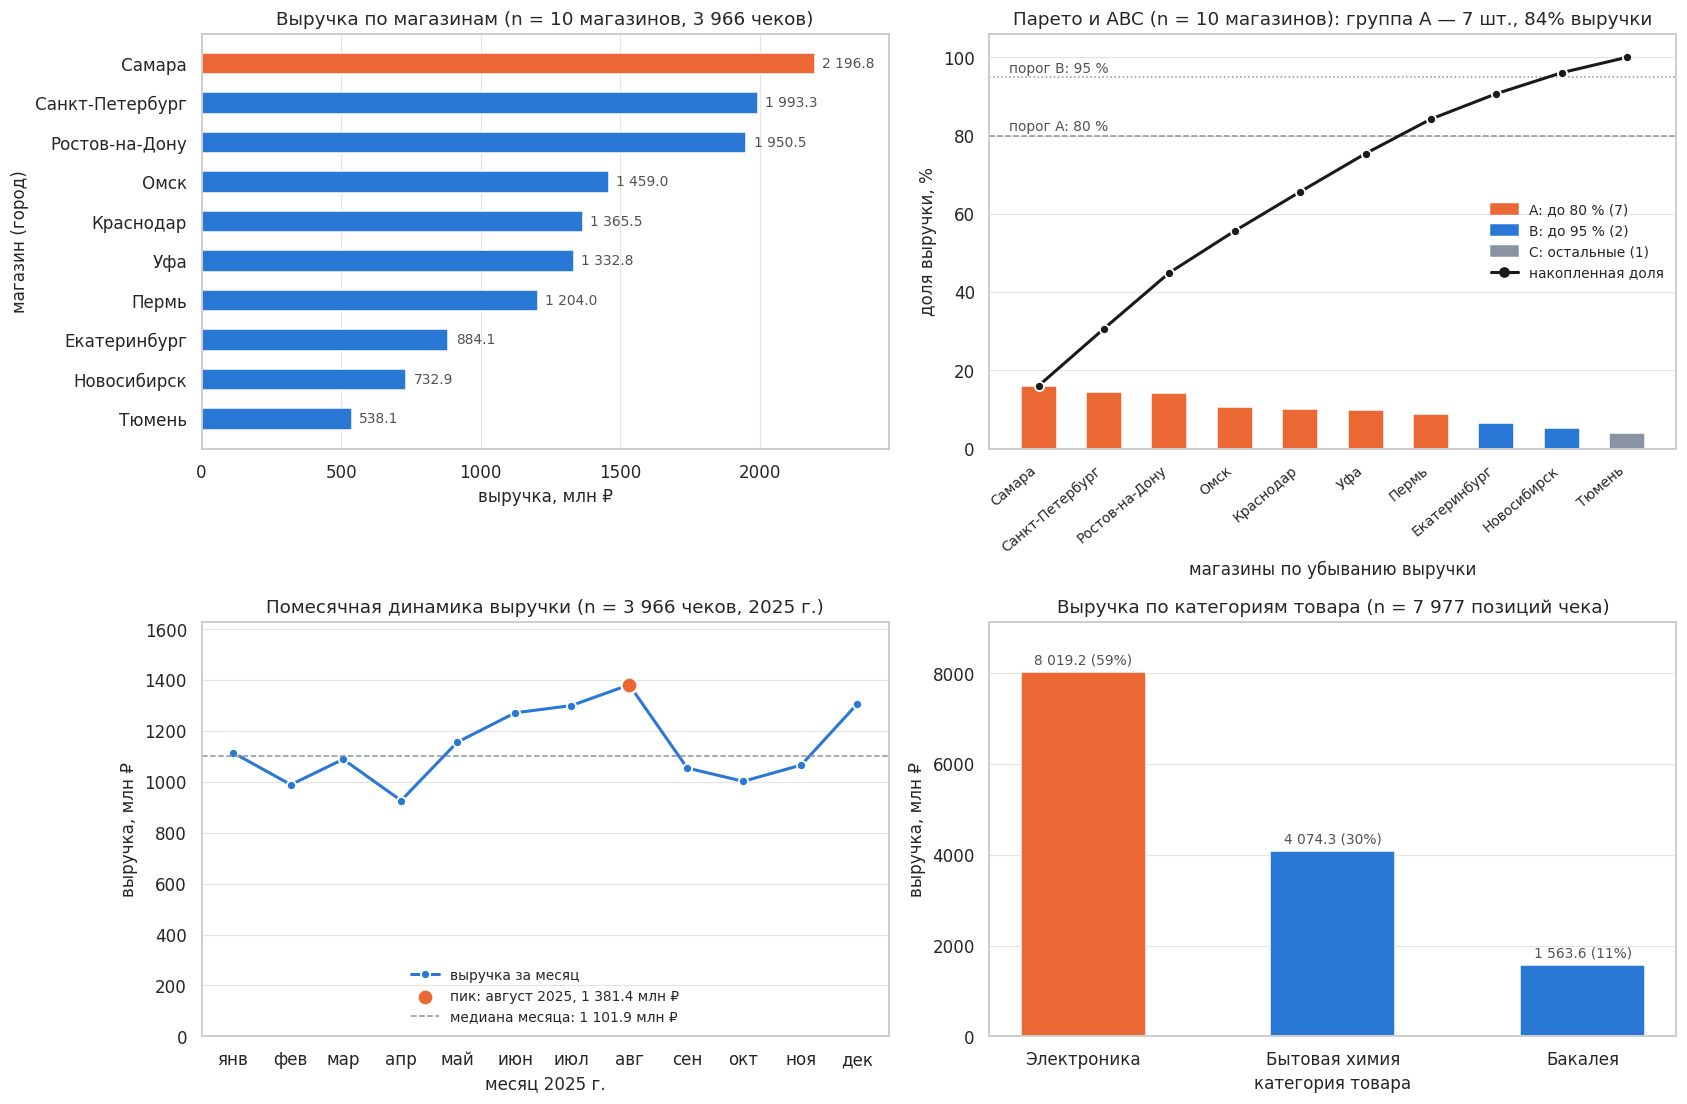


ABC-АНАЛИЗ МАГАЗИНОВ


,магазин,"выручка, ₽","доля, %","накопленная, %",группа
0,Самара,"2,196,809,757.00",16.10,16.10,A
1,Санкт-Петербург,"1,993,303,122.00",14.60,30.70,A
2,Ростов-на-Дону,"1,950,497,469.00",14.30,45.00,A
3,Омск,"1,458,964,612.00",10.70,55.60,A
4,Краснодар,"1,365,541,885.00",10.00,65.60,A
5,Уфа,"1,332,798,927.00",9.80,75.40,A
6,Пермь,"1,203,966,779.00",8.80,84.20,A
7,Екатеринбург,"884,073,909.00",6.50,90.70,B
8,Новосибирск,"732,932,755.00",5.40,96.10,B
9,Тюмень,"538,102,977.00",3.90,100.00,C



================== ВЫВОДЫ ДЛЯ ЛПР ==================
Предметная область : Розничная сеть (вариант 2)
Данные             : 3 967 чеков, 7 977 позиций, 10 магазинов;
                     в карантине 135 строк (1.1%)
Итоговая выручка   : 13 657.0 млн ₽ (корректный расчёт); наивный JOIN дал бы 27 448.5 млн ₽ (в 2.01 раза больше)

1. Концентрация (ABC). Порог 80 % выручки достигается на 7-м магазине из 10: группа A — Самара, Санкт-Петербург, Ростов-на-Дону, Омск, Краснодар, Уфа, Пермь
   (вместе 84.2%). Лидер — «Самара» (16.1%), три крупнейших дают 45%. Группа B — 2
   (12%), группа C — 1 (4%): Тюмень. Классического «20/80» нет: для 80 %
   нужно 70% магазинов — выручка распределена по сети сравнительно ровно.
2. Что отличает магазины. Средний чек: группа A — 3.43 млн ₽, хвост (Екатеринбург, Новосибирск, Тюмень) — 3.53 млн ₽
   (+3%); число чеков на магазин: 479 против 203 (2.4 раза). Разрыв между группами
   определяется в основном числом чеков (трафиком).
3. Сезонность. Пик — август 2025

In [7]:
#@title Шаг 6. Аналитика и визуализация (решение) { display-mode: "form" }
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

# Палитра: синий — базовый цвет, оранжевый — единственный акцент на выделяемый объект, серый — «остальное».
# Пара синий/оранжевый прошла проверку на различимость при дальтонизме (ΔE ≥ 24) и контраст ≥ 3:1.
BASE, ACCENT, MUTED = "#2a78d6", "#eb6834", "#8a93a3"
INK, INK2 = "#1a1a1a", "#52514e"
RU_MONTHS = ["январь", "февраль", "март", "апрель", "май", "июнь",
             "июль", "август", "сентябрь", "октябрь", "ноябрь", "декабрь"]
RU_MONTHS_SHORT = ["янв", "фев", "мар", "апр", "май", "июн", "июл", "авг", "сен", "окт", "ноя", "дек"]
def ru_month(ts):
    return f"{RU_MONTHS[ts.month - 1]} {ts.year}"
def city(name):                                    # «Магазины «Москва»» → «Москва»
    m = re.search(r"«(.+?)»", str(name))
    return m.group(1) if m else str(name)

total_revenue = float(revenue_sql["revenue"].sum())
n_events = len(consolidated)

# ---------------------------------------------------------------- подготовка срезов
# ABC: группа A — минимальный набор магазинов, который набирает 80 % выручки (магазин, пересекающий
# порог, входит в A); B — до 95 %; C — остальные. Так ответ на вопрос «какие точки дают 80 %» однозначен.
pareto = revenue_sql.sort_values("revenue", ascending=False).reset_index(drop=True)
pareto["магазин"] = pareto["entity_name"].map(city)
pareto["доля"] = pareto["revenue"] / total_revenue
pareto["накопленная доля"] = pareto["доля"].cumsum()
share_before = pareto["накопленная доля"] - pareto["доля"]
pareto["группа ABC"] = np.where(share_before < 0.80, "A", np.where(share_before < 0.95, "B", "C"))

monthly = (consolidated.assign(month=consolidated["event_date"].dt.to_period("M").dt.to_timestamp())
           .groupby("month", as_index=False)
           .agg(revenue=("event_revenue", "sum"), events=("event_id", "count")))

# Разрез по категориям цен: выручку события делим между его ценовыми строками поровну — иначе тот же fan-out
# завысит сумму. Контроль сходимости ниже обязан дать 0.
by_class = (prices_valid.merge(events_valid[["event_id", "volume_units"]], on="event_id")
            .assign(n_rows=lambda d: d.groupby("event_id")["price_id"].transform("count"))
            .assign(revenue=lambda d: d["volume_units"] * d["unit_price"] / d["n_rows"])
            .groupby("price_class", as_index=False)["revenue"].sum()
            .sort_values("revenue", ascending=False).reset_index(drop=True))

gaps = {
    f"разрез цен ({CFG['cls']})": abs(float(by_class["revenue"].sum()) - total_revenue),
    "месяцы": abs(float(monthly["revenue"].sum()) - total_revenue),
    "группы ABC": abs(float(pareto.groupby("группа ABC")["revenue"].sum().sum()) - total_revenue),
    f"способ оплаты ({DETAIL_COL})": abs(float(consolidated["event_revenue"].sum()) - total_revenue),
}
print("КОНТРОЛЬ СХОДИМОСТИ: сумма по срезу минус итоговая выручка, ₽ (должно быть 0 с точностью округления)")
for k, v in gaps.items():
    print(f"  {k:<42}{v:>12.2f}")
class_gap = gaps[f"разрез цен ({CFG['cls']})"]

# ---------------------------------------------------------------- графики
fig, axes = plt.subplots(2, 2, figsize=(15.5, 10.2))
for ax_, g_axis in zip(axes.flat, ["x", "y", "y", "y"]):          # сетка только по оси значений, светлая
    ax_.grid(False)
    ax_.grid(axis=g_axis, color="#e4e4e0", lw=0.8)
    ax_.set_axisbelow(True)

# 1. Выручка по магазинам, лидер выделен
ax = axes[0, 0]
top = pareto.sort_values("revenue")                       # по возрастанию: лидер окажется сверху
vals = top["revenue"] / 1e6
ax.barh(top["магазин"], vals, height=0.55, color=[ACCENT if i == len(top) - 1 else BASE for i in range(len(top))])
for y, v in enumerate(vals):
    ax.text(v + vals.max() * 0.012, y, nf(v, 1), va="center", fontsize=9, color=INK2)
ax.set_xlim(0, vals.max() * 1.12)
ax.set_title(f"Выручка по магазинам (n = {len(top)} магазинов, {nf(n_events)} чеков)")
ax.set_xlabel("выручка, млн ₽"); ax.set_ylabel("магазин (город)")

# 2. Диаграмма Парето: столбцы — доля магазина, линия — накопленная доля; одна общая шкала, %
ax = axes[0, 1]
x = np.arange(len(pareto))
grp = {"A": ACCENT, "B": BASE, "C": MUTED}
ax.bar(x, pareto["доля"] * 100, width=0.55, color=[grp[g] for g in pareto["группа ABC"]])
ax.plot(x, pareto["накопленная доля"] * 100, color=INK, lw=2, marker="o", ms=6, mec="white", mew=1.2, zorder=3)
ax.axhline(80, color=MUTED, lw=1, ls="--"); ax.axhline(95, color=MUTED, lw=1, ls=":")
ax.text(-0.45, 81.2, "порог A: 80 %", ha="left", fontsize=9, color=INK2)
ax.text(-0.45, 96.2, "порог B: 95 %", ha="left", fontsize=9, color=INK2)
ax.set_xticks(x); ax.set_xticklabels(pareto["магазин"], rotation=40, ha="right", fontsize=9)
ax.set_ylim(0, 106)
n_abc = pareto["группа ABC"].value_counts().reindex(["A", "B", "C"]).fillna(0).astype(int)
share_abc = pareto.groupby("группа ABC")["доля"].sum().reindex(["A", "B", "C"]).fillna(0)
ax.set_title(f"Парето и ABC (n = {len(pareto)} магазинов): группа A — {n_abc['A']} шт., {share_abc['A']:.0%} выручки")
ax.set_xlabel("магазины по убыванию выручки"); ax.set_ylabel("доля выручки, %")
ax.legend(handles=[Patch(color=ACCENT, label=f"A: до 80 % ({n_abc['A']})"),
                   Patch(color=BASE, label=f"B: до 95 % ({n_abc['B']})"),
                   Patch(color=MUTED, label=f"C: остальные ({n_abc['C']})"),
                   Line2D([0], [0], color=INK, lw=2, marker="o", ms=6, label="накопленная доля")],
          loc="center right", fontsize=9, frameon=False)

# 3. Сезонность: пик выделен, медиана — пунктир
ax = axes[1, 0]
mv = monthly["revenue"] / 1e6
ax.plot(monthly["month"], mv, color=BASE, lw=2, marker="o", ms=6, mec="white", mew=1.2, label="выручка за месяц")
peak = monthly.loc[monthly["revenue"].idxmax()]
low = monthly.loc[monthly["revenue"].idxmin()]
ax.scatter([peak["month"]], [peak["revenue"] / 1e6], color=ACCENT, s=110, zorder=4, edgecolor="white", linewidth=1.5,
           label=f"пик: {ru_month(peak['month'])}, {nf(peak['revenue'] / 1e6, 1)} млн ₽")
ax.axhline(monthly["revenue"].median() / 1e6, color=MUTED, lw=1, ls="--",
           label=f"медиана месяца: {nf(monthly['revenue'].median() / 1e6, 1)} млн ₽")
ax.set_xticks(monthly["month"]); ax.set_xticklabels([RU_MONTHS_SHORT[m.month - 1] for m in monthly["month"]])
ax.set_ylim(0, mv.max() * 1.18)
ax.set_title(f"Помесячная динамика выручки (n = {nf(n_events)} чеков, {monthly['month'].min().year} г.)")
ax.set_xlabel(f"месяц {monthly['month'].min().year} г."); ax.set_ylabel("выручка, млн ₽")
ax.legend(fontsize=9, loc="lower center", ncol=1, frameon=False)

# 4. Структура по категориям товара (разрез цен)
ax = axes[1, 1]
cv = by_class["revenue"] / 1e6
ax.bar(by_class["price_class"], cv, width=0.5, color=[ACCENT if i == 0 else BASE for i in range(len(by_class))])
for i, (v, s) in enumerate(zip(cv, by_class["revenue"] / total_revenue)):
    ax.text(i, v + cv.max() * 0.015, f"{nf(v, 1)} ({s:.0%})", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_ylim(0, cv.max() * 1.14)
ax.set_title(f"Выручка по категориям товара (n = {nf(len(prices_valid))} позиций чека)")
ax.set_xlabel(CFG["cls"]); ax.set_ylabel("выручка, млн ₽")

plt.tight_layout()
fig.savefig(WORK / "charts.png", dpi=130, bbox_inches="tight")
plt.show()
PLOTS_DONE = True

abc_table = pd.DataFrame({
    "магазин": pareto["магазин"], "выручка, ₽": pareto["revenue"].round(0),
    "доля, %": (pareto["доля"] * 100).round(1), "накопленная, %": (pareto["накопленная доля"] * 100).round(1),
    "группа": pareto["группа ABC"]})
print("\nABC-АНАЛИЗ МАГАЗИНОВ")
display(abc_table)

# ---------------------------------------------------------------- выводы для ЛПР
leader = pareto.iloc[0]
group_a = pareto[pareto["группа ABC"] == "A"]["магазин"].tolist()
group_c = pareto[pareto["группа ABC"] == "C"]["магазин"].tolist()
share_top3 = float(pareto["доля"].head(3).sum())
season_gap = float(monthly["revenue"].max() / monthly["revenue"].min())
avg_month = float(monthly["revenue"].mean())
peak_up = float(peak["revenue"] / avg_month - 1)
low_down = float(1 - low["revenue"] / avg_month)
top_class = by_class.iloc[0]
top_class_share = float(top_class["revenue"] / total_revenue)

# выручка, застрявшая в карантине: события с неизвестным магазином, у которых есть и объём, и цена
q_ev = quarantine_fk[quarantine_fk["volume_units"].gt(0)].merge(
    prices_ok.groupby("event_id")["unit_price"].mean().rename("avg_price"), left_on="event_id", right_index=True)
stuck_revenue = float((q_ev["volume_units"] * q_ev["avg_price"]).sum())
lost_share = lost_total / max(len(raw_events) + len(raw_prices), 1)
c_gain = 0.10 * float(share_abc["C"]) * total_revenue
pareto["revenue_per_check"] = pareto["revenue"] / pareto["events_cnt"]       # выручка на один чек, ₽
a_part, tail = pareto[pareto["группа ABC"] == "A"], pareto[pareto["группа ABC"] != "A"]
chk_a = float(a_part["revenue"].sum() / a_part["events_cnt"].sum())           # средний чек группы A
chk_t = float(tail["revenue"].sum() / tail["events_cnt"].sum())               # средний чек хвоста
cnt_a, cnt_t = float(a_part["events_cnt"].mean()), float(tail["events_cnt"].mean())
chk_diff, cnt_ratio = chk_t / chk_a - 1, cnt_a / cnt_t
gap_driver = "числом чеков (трафиком)" if abs(chk_diff) < (cnt_ratio - 1) / 2 else "размером чека"
mln = lambda v: nf(v / 1e6, 1) + " млн ₽"
orphan_ids = ", ".join(sorted(quarantine_fk["entity_id"].astype(str).unique()))

print(f"""
================== ВЫВОДЫ ДЛЯ ЛПР ==================
Предметная область : {CFG['domain']} (вариант {VARIANT})
Данные             : {nf(len(events_valid))} чеков, {nf(len(prices_valid))} позиций, {len(entities)} магазинов;
                     в карантине {nf(lost_total)} строк ({lost_share:.1%})
Итоговая выручка   : {mln(total_revenue)} (корректный расчёт); наивный JOIN дал бы {mln(compare['revenue_naive'].sum())} (в {overstate:.2f} раза больше)

1. Концентрация (ABC). Порог 80 % выручки достигается на {n_abc['A']}-м магазине из {len(pareto)}: группа A — {', '.join(group_a)}
   (вместе {share_abc['A']:.1%}). Лидер — «{leader['магазин']}» ({leader['доля']:.1%}), три крупнейших дают {share_top3:.0%}. Группа B — {n_abc['B']}
   ({share_abc['B']:.0%}), группа C — {n_abc['C']} ({share_abc['C']:.0%}): {', '.join(group_c) if group_c else '—'}. Классического «20/80» нет: для 80 %
   нужно {n_abc['A'] / len(pareto):.0%} магазинов — выручка распределена по сети сравнительно ровно.
2. Что отличает магазины. Средний чек: группа A — {nf(chk_a / 1e6, 2)} млн ₽, хвост ({', '.join(tail['магазин'])}) — {nf(chk_t / 1e6, 2)} млн ₽
   ({chk_diff:+.0%}); число чеков на магазин: {nf(cnt_a)} против {nf(cnt_t)} ({cnt_ratio:.1f} раза). Разрыв между группами
   определяется в основном {gap_driver}.
3. Сезонность. Пик — {ru_month(peak['month'])} ({peak_up:+.0%} к среднемесячному), минимум — {ru_month(low['month'])} (−{low_down:.0%}); разрыв
   максимума и минимума — {season_gap:.2f} раза. Планирование по среднегодовому значению даст дефицит в пик и простой в низкий сезон.
4. Структура. Категория «{top_class['price_class']}» даёт {top_class_share:.0%} выручки: сеть зависит от одной дорогой категории, и её
   ассортимент и запасы — приоритет контроля.
5. Качество данных. Наивное соединение таблиц завышало выручку в {overstate:.2f} раза (объём — в {vol_overstate:.2f}). В карантине осталось
   ещё ≈ {mln(stuck_revenue)} выручки ({stuck_revenue / total_revenue:.1%} к итогу): чеки с несуществующим магазином ({orphan_ids}).

Рекомендации (эффект — расчётный сценарий, проверка — контрольный показатель):
• Закрепить в регламенте корректную методику (свёртка цен до уровня события) и ввести контроль входа: ссылочная целостность,
  диапазоны, дубликаты, автотест «SQL = pandas». Эффект: отчётность перестаёт завышаться в {overstate:.2f} раза; после разбора карантина
  с владельцем данных в отчёт возвращается ≈ {mln(stuck_revenue)}. Проверка: баланс строк = 0 и расхождение SQL/pandas < 1 ₽ при каждой загрузке.
• Управлять по ABC: группа A ({n_abc['A']} магазинов) — удержание и тиражирование практик лидеров; хвост B и C (магазинов: {len(tail)},
  {tail['доля'].sum():.0%} выручки) — разбор причин отставания (трафик, локация, ассортимент, график работы). Эффект: рост выручки группы C
  на 10 % даёт ≈ +{mln(c_gain)} ({c_gain / total_revenue:.1%} к итогу). Проверка: доли A/B/C и выручка группы C в следующем квартале.
• Планировать запасы и смены по помесячному профилю, а не по среднему. Эффект: заложить в пик ≈ {peak_up:+.0%} к среднемесячному объёму,
  в минимум — −{low_down:.0%}. Проверка: отклонение факта от помесячного плана.

Ограничения данных: цена по событию — простое среднее (нет числа проданных единиц по категориям, см. задание D); события без пригодной цены
({events_no_price}) в выручку не входят; один календарный год — сезонность наблюдается по одному циклу; пропуск region у магазина оставлен
пропуском (восстановим по названию только после согласования с владельцем справочника).
====================================================
""")

**Интерпретация.** На диаграмме Парето смотрите, сколько субъектов попало в группу A: это и есть ответ на вопрос «где сосредоточено управленческое внимание». На сезонности сравните пик и провал: разрыв в полтора-два раза означает, что планирование по среднегодовому значению даст дефицит мощностей летом и простой зимой. В структуре по классам главное — строка контроля сходимости: ноль подтверждает, что при разрезании выручки вы не размножили её повторно.

Выводы для ЛПР — не пересказ графиков, а решения: что делать, на каком основании и как проверить результат.

### Экспорт витрины

В репозиторий сдаются ноутбук, файл базы `*.sqlite` и выгрузка витрины. Ячейка ниже сохраняет витрину (выручка и ABC по магазинам, месяцам, категориям, уровень чека), реестр карантина и журналы очистки в CSV.

In [8]:
#@title Экспорт витрины и карантина (для репозитория GitHub) { display-mode: "form" }
# В репозиторий сдаются: ноутбук с выводами, файл базы *.sqlite и выгрузка витрины (CSV).
# Кодировка utf-8-sig: файлы одинаково открываются в Excel и в pandas.
EXPORT = WORK / "export"
EXPORT.mkdir(exist_ok=True)

mart_entity = revenue_sql.merge(
    pareto[["entity_id", "доля", "накопленная доля", "группа ABC"]], on="entity_id", how="left")
mart_entity = mart_entity.rename(columns={"доля": "revenue_share", "накопленная доля": "revenue_share_cum",
                                          "группа ABC": "abc_group"})
mart_event = consolidated[["event_id", "entity_id", "entity_name", "event_date", DETAIL_COL, KIND_COL,
                           "volume_units", "unit_price", "event_revenue"]].rename(columns={"unit_price": "avg_price"})
mart_event = mart_event.assign(event_date=mart_event["event_date"].dt.strftime("%Y-%m-%d"))

exports = {
    "mart_revenue_by_entity.csv": mart_entity,                                    # витрина: выручка и ABC по магазинам
    "mart_revenue_by_month.csv": monthly.assign(month=monthly["month"].dt.strftime("%Y-%m")),
    "mart_revenue_by_class.csv": by_class,
    "mart_event_level.csv": mart_event,                                           # уровень чека: событие × средняя цена
    "quarantine.csv": quarantine_all,                                             # что не вошло в расчёт и почему
    "cleaning_log.csv": clean_log_df,
    "quality_issues.csv": quality,
}
for fname, frame in exports.items():
    frame.to_csv(EXPORT / fname, index=False, encoding="utf-8-sig")

print(f"Выгрузка в {EXPORT}:")
for fname, frame in exports.items():
    print(f"  {fname:<30}{nf(len(frame)):>8} строк  {(EXPORT / fname).stat().st_size / 1024:8.1f} КБ")
print(f"\nБаза SQLite: {DB_PATH.name} ({DB_PATH.stat().st_size / 1024:.0f} КБ); график: charts.png")

Выгрузка в /content/pw2/export:
  mart_revenue_by_entity.csv          10 строк       1.4 КБ
  mart_revenue_by_month.csv           12 строк       0.4 КБ
  mart_revenue_by_class.csv            3 строк       0.1 КБ
  mart_event_level.csv             3 966 строк     556.2 КБ
  quarantine.csv                     135 строк       9.8 КБ
  cleaning_log.csv                    10 строк       2.0 КБ
  quality_issues.csv                  21 строк       3.8 КБ

База SQLite: consolidation_variant_2.sqlite (1296 КБ); график: charts.png


## Шаг 7. BigQuery: пошаговое подключение из Colab

Показать, как та же витрина переносится в облачное хранилище, когда данных становится слишком много для одной машины.

### Шаг 1. Аккаунт и проект

1. Откройте <https://console.cloud.google.com> и войдите в аккаунт Google.
2. Вверху нажмите селектор проектов → **New Project**, задайте имя (например, `pw2-consolidation`) и создайте проект.
3. Скопируйте **Project ID** — это не название, а идентификатор вида `pw2-consolidation-123456`. Он понадобится в коде.

### Шаг 2. Режим работы: sandbox или биллинг

* **BigQuery sandbox** — без привязки карты. Бесплатно: 10 ГБ хранения и 1 ТБ обработанных запросами данных в месяц. Ограничения: нет DML-операций в части сценариев, таблицы автоматически удаляются через 60 дней. Для этой работы sandbox достаточно.
* **С биллингом** — снимаются ограничения sandbox, бесплатные лимиты те же. Карта привязывается в разделе **Billing**.

### Шаг 3. Включение API

В консоли: **APIs & Services → Library → BigQuery API → Enable**. Без этого библиотека вернёт ошибку доступа.

### Шаг 4. Аутентификация в Colab

```python
from google.colab import auth
auth.authenticate_user()     # откроется окно входа в Google-аккаунт
```

Вне Colab используется либо `gcloud auth application-default login`, либо ключ сервисного аккаунта: **IAM & Admin → Service Accounts → Create** → роль **BigQuery Data Editor** и **BigQuery Job User** → **Keys → Add key (JSON)**. Путь к файлу ключа кладётся в переменную окружения `GOOGLE_APPLICATION_CREDENTIALS`.

> Файл ключа — это пароль от проекта. Его нельзя коммитить в репозиторий и нельзя оставлять в выводе ячейки.

### Шаг 5. Датасет

Датасет — контейнер таблиц с привязкой к региону (`US`, `EU`, `europe-west3`). Регион выбирается один раз: соединять таблицы из разных регионов нельзя. Создаётся кодом в ячейке ниже (`create_dataset(..., exists_ok=True)`) или в консоли кнопкой **Create dataset**.

### Шаг 6. Загрузка и запрос

Код ячейки делает следующее:

1. загружает три очищенные таблицы через `load_table_from_dataframe` с режимом `WRITE_TRUNCATE` (перезапись — повторный запуск не плодит дубликаты);
2. выполняет **сухой прогон** (`dry_run=True`), который показывает, сколько байт прочитает запрос, ничего не тратя, — привычка, экономящая бюджет;
3. выполняет тот же корректный расчёт выручки, что и в SQLite;
4. сверяет результат с SQLite: цифры обязаны совпасть.

### Шаг 7. Стоимость и правила экономии

Оплата в BigQuery берётся за **объём прочитанных данных**, а не за время. Отсюда практические правила:

* не писать `SELECT *` — читаются только перечисленные колонки (колоночное хранение);
* использовать партиционирование по дате и кластеризацию по ключу фильтрации;
* перед тяжёлым запросом делать `dry_run`;
* учебные наборы этой работы весят единицы мегабайт, то есть укладываются в бесплатный лимит с огромным запасом.

### Отличия синтаксиса от SQLite

| | SQLite | BigQuery (GoogleSQL) |
|---|---|---|
| Идентификаторы | `"table"` или без кавычек | `` `project.dataset.table` `` |
| Типы дат | текст `YYYY-MM-DD` | `DATE`, `TIMESTAMP` |
| Приведение типа | `CAST(x AS REAL)` | `CAST(x AS FLOAT64)`, `SAFE_CAST` |
| Ключи | `PRIMARY KEY`, `FOREIGN KEY` | ограничения не проверяются: целостность обеспечивает конвейер |
| Пагинация | `LIMIT n OFFSET m` | `LIMIT n OFFSET m`, но для больших выборок — экспорт |

Последняя строка таблицы — важный профессиональный вывод: в аналитических хранилищах контроль качества не делегируется базе. Всё, что вы сделали на шагах 3–4, в промышленном контуре становится обязательным этапом конвейера.

In [9]:
#@title Шаг 7. Выгрузка витрины в BigQuery { display-mode: "form" }
# Ячейка ничего не делает, пока ENABLE_BIGQUERY = False в шаге 1.
# Перед включением выполните шаги из markdown-инструкции выше: проект, sandbox, датасет.
BQ_PROJECT_ID = "my-gcp-project"   #@param {type:"string"}
BQ_DATASET = "pw2_consolidation"   #@param {type:"string"}
BQ_LOCATION = "US"                 #@param ["US", "EU", "europe-west3", "asia-northeast1"]

if not ENABLE_BIGQUERY:
    print("BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: "
          "основная часть работы выполняется на SQLite.")
else:
    ensure("google-cloud-bigquery", "google.cloud.bigquery")
    ensure("pandas-gbq", "pandas_gbq")
    from google.cloud import bigquery

    # 1. Аутентификация: в Colab открывает окно входа в Google-аккаунт
    try:
        from google.colab import auth
        auth.authenticate_user()
        print("Аутентификация в Colab выполнена")
    except ImportError:
        print("Не Colab: используйте `gcloud auth application-default login` "
              "или переменную GOOGLE_APPLICATION_CREDENTIALS с путём к ключу сервисного аккаунта")

    client = bigquery.Client(project=BQ_PROJECT_ID, location=BQ_LOCATION)

    # 2. Датасет создаётся, если его ещё нет
    dataset_ref = bigquery.Dataset(f"{BQ_PROJECT_ID}.{BQ_DATASET}")
    dataset_ref.location = BQ_LOCATION
    client.create_dataset(dataset_ref, exists_ok=True)
    print(f"Датасет готов: {BQ_PROJECT_ID}.{BQ_DATASET} ({BQ_LOCATION})")

    # 3. Загрузка трёх очищенных таблиц
    for name, frame in [("entities", entities),
                        ("events", events_out),
                        ("prices", prices_valid[["price_id", "event_id", "unit_price", "price_class"]])]:
        job = client.load_table_from_dataframe(
            frame, f"{BQ_PROJECT_ID}.{BQ_DATASET}.{name}",
            job_config=bigquery.LoadJobConfig(write_disposition="WRITE_TRUNCATE"))
        job.result()
        print(f"  загружено {name}: {nf(len(frame))} строк")

    # 4. Тот же корректный расчёт выручки, но на стороне BigQuery
    bq_sql = f"""
    WITH price_per_event AS (
        SELECT event_id, AVG(unit_price) AS avg_price
        FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.prices`
        GROUP BY event_id
    )
    SELECT e.entity_name,
           COUNT(ev.event_id)                            AS events_cnt,
           ROUND(SUM(ev.volume_units * pe.avg_price), 2) AS revenue
    FROM `{BQ_PROJECT_ID}.{BQ_DATASET}.entities` e
    JOIN `{BQ_PROJECT_ID}.{BQ_DATASET}.events` ev ON ev.entity_id = e.entity_id
    JOIN price_per_event pe ON pe.event_id = ev.event_id
    GROUP BY e.entity_name
    ORDER BY revenue DESC
    """

    # 5. Сухой прогон: сколько байт прочитает запрос (в sandbox бесплатно 1 ТБ в месяц)
    dry = client.query(bq_sql, job_config=bigquery.QueryJobConfig(dry_run=True, use_query_cache=False))
    print(f"\nОценка объёма чтения: {dry.total_bytes_processed / 1024**2:.2f} МБ "
          f"(бесплатный лимит — 1 ТБ в месяц)")

    revenue_bq = client.query(bq_sql).to_dataframe()
    display(revenue_bq.head(10))

    # 6. Сверка с SQLite: цифры обязаны совпасть
    check = (revenue_bq.set_index("entity_name")["revenue"]
             - revenue_sql.set_index("entity_name")["revenue"]).abs().max()
    print(f"Максимальное расхождение BigQuery и SQLite: {check:.4f}")

BigQuery отключён (ENABLE_BIGQUERY = False). Раздел необязателен: основная часть работы выполняется на SQLite.


## Таблица вариантов (30 вариантов)

Номер варианта выдаёт преподаватель; он подставляется в поле `VARIANT` шага 1 и определяет предметную область, объём генерации и набор дефектов (столбец «Дефекты»: ★ — базовый набор, ★★ — добавляются битые внешние ключи и отрицательные цены, ★★★ — ещё и дубликаты записей).

Архитектура данных во всех вариантах одинакова: справочник субъектов (CSV) → события с объёмом (XLSX) → цены по событиям, несколько строк на событие (JSON). Считается выручка по субъектам.

| № | Предметная область | CSV: справочник | XLSX: события | JSON: цены | Единица объёма | Разрез цен | Аналитическая задача | Дефекты |
|---:|---|---|---|---|---|---|---|:--:|
| 1 | Авиаперевозки | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Сезонность перевозок: в каком месяце выручка максимальна и какие компании её формируют | ★★ |
| 2 | Розничная сеть | Магазины | Чеки | Позиции чека | единиц товара | категория товара | ABC-анализ магазинов: какие точки дают 80 % выручки | ★★★ |
| 3 | Логистика | Перевозчики | Отгрузки | Тарифы | паллет | тип тарифа | Загрузка перевозчиков: связь объёма и средней ставки | ★ |
| 4 | Телеком | Операторы | Сессии связи | Тарификация | минут | тарифный план | Доля тарифных планов в выручке и средний чек сессии | ★★ |
| 5 | Банковский ритейл | Отделения | Операции | Комиссии | транзакций | тип комиссии | Эффективность отделений: выручка на одну операцию | ★★★ |
| 6 | Гостиничный бизнес | Отели | Бронирования | Тарифы номеров | ночей | категория номера | Сезонность загрузки и вклад категорий номеров | ★ |
| 7 | Образовательные услуги | Центры | Группы | Стоимость обучения | слушателей | формат обучения | Выручка на слушателя и сравнение форматов | ★★ |
| 8 | Медицинские клиники | Клиники | Приёмы | Прейскурант | пациентов | вид услуги | Структура выручки по видам услуг и загрузка клиник | ★★★ |
| 9 | Энергосбыт | Сбытовые компании | Поставки | Тарифы | МВт·ч | категория потребителя | Концентрация выручки по категориям потребителей | ★ |
| 10 | Маркетплейс | Продавцы | Заказы | Цены товаров | единиц | категория товара | Топ продавцов и доля категорий в обороте | ★★ |
| 11 | Общественный транспорт | Перевозчики | Маршруты-рейсы | Тарифы проезда | пассажиров | тип билета | Выручка по типам билетов и пиковые месяцы | ★★★ |
| 12 | Страхование | Агентства | Договоры | Тарифные ставки | объектов | вид страхования | Средняя премия по видам страхования и вклад агентств | ★ |
| 13 | Грузовые ж/д перевозки | Операторы вагонов | Отправки | Ставки | тонн | род груза | Доходность по родам груза и сезонность отправок | ★★ |
| 14 | Общепит | Рестораны | Заказы | Цены блюд | порций | категория меню | Средний чек и вклад категорий меню | ★★★ |
| 15 | Фитнес-сети | Клубы | Визиты и покупки | Прайс услуг | услуг | тип абонемента | Выручка на клуб и структура абонементов | ★ |
| 16 | Аренда спецтехники | Парки техники | Смены аренды | Ставки аренды | машино-часов | тип техники | Утилизация парка и доходность типов техники | ★★ |
| 17 | Курьерская доставка | Службы доставки | Доставки | Тарифы | посылок | скорость доставки | Доля экспресс-доставки в выручке | ★★★ |
| 18 | Оптовая торговля | Дистрибьюторы | Поставки | Прайс-листы | коробов | товарная группа | Парето по товарным группам и вклад дистрибьюторов | ★ |
| 19 | Автосервис | Сервисные центры | Заказ-наряды | Прейскурант работ | нормо-часов | вид работ | Выручка по видам работ и загрузка центров | ★★ |
| 20 | Цифровые подписки | Сервисы | Подписки | Тарифные планы | подписчиков | план подписки | Структура подписной базы и выручка на подписчика | ★★★ |
| 21 | Сельхозпроизводство | Хозяйства | Партии отгрузки | Закупочные цены | тонн | культура | Доходность культур и сезонность отгрузок | ★ |
| 22 | Строительный ритейл | Гипермаркеты | Продажи | Цены материалов | единиц | группа материалов | Сезонность продаж и вклад групп материалов | ★★ |
| 23 | Морские перевозки | Судоходные линии | Рейсы судов | Фрахтовые ставки | TEU | тип контейнера | Доходность линий и структура по типам контейнеров | ★★★ |
| 24 | Аптечные сети | Аптеки | Продажи | Цены препаратов | упаковок | группа препаратов | Вклад товарных групп и сравнение точек | ★ |
| 25 | Кинотеатры | Кинотеатры | Сеансы | Цены билетов | зрителей | тип сеанса | Заполняемость залов и выручка по типам сеансов | ★★ |
| 26 | Промышленное производство | Заводы | Партии продукции | Отпускные цены | тонн | марка продукции | Вклад марок продукции и сезонность отгрузок | ★★★ |
| 27 | Рекламные площадки | Площадки | Кампании | Ставки размещения | показов (тыс.) | формат размещения | Доходность форматов и концентрация выручки | ★ |
| 28 | ЖКХ | Управляющие компании | Начисления | Тарифы услуг | объектов | вид услуги | Структура начислений и сравнение управляющих компаний | ★★ |
| 29 | Каршеринг | Операторы | Поездки | Тарифы поездок | минут | класс автомобиля | Выручка на поездку и вклад классов автомобилей | ★★★ |
| 30 | Авиаперевозки (эталон преподавателя) | Авиакомпании | Рейсы | Билеты | пассажиров | класс билета | Полный разбор: качество данных, fan-out при JOIN, сезонность, концентрация выручки | ★ |

Минимум для зачёта: найдено не менее пяти проблем качества, заполнен журнал очистки, показана разница наивного и корректного расчёта, результаты SQL и pandas сошлись.

### Описательные столбцы событий и классы цен по вариантам

| № | Предметная область | Столбцы `events.xlsx` (кроме ключей, даты и объёма) | Классы цен в `prices.json` |
|---:|---|---|---|
| 1 | Авиаперевозки | `route`: «город — город»; `aircraft_type`: Узкофюзеляжный, Широкофюзеляжный, Региональный, Турбовинтовой | Эконом, Комфорт, Бизнес |
| 2 | Розничная сеть | `payment_method`: Наличные, Банковская карта, СБП, Карта + бонусы; `checkout_type`: Касса, Касса самообслуживания, Онлайн-заказ, Экспресс-касса | Бакалея, Бытовая химия, Электроника |
| 3 | Логистика | `route`: «город — город»; `vehicle_type`: Фура 20 т, Рефрижератор, Малотоннажный, Контейнеровоз | Базовый, Срочный, Экспресс |
| 4 | Телеком | `network`: 2G, 3G, 4G, 5G; `session_type`: Голос, Мобильный интернет, Роуминг, SMS-пакет | Базовый, Безлимитный, Корпоративный |
| 5 | Банковский ритейл | `service_channel`: Касса, Банкомат, Интернет-банк, Мобильное приложение; `client_segment`: Массовый, Зарплатный, Премиальный, МСБ | Переводы, Валютные операции, Инкассация |
| 6 | Гостиничный бизнес | `booking_channel`: Сайт отеля, Онлайн-агрегатор, Турагентство, Корпоративный договор; `guest_type`: Деловой, Туристический, Семейный, Групповой | Стандарт, Делюкс, Люкс |
| 7 | Образовательные услуги | `course_area`: IT, Иностранные языки, Управление, Подготовка к экзаменам; `audience`: Школьники, Студенты, Взрослые, Корпоративные клиенты | Онлайн, Смешанный, Очный |
| 8 | Медицинские клиники | `specialty`: Терапия, Педиатрия, Стоматология, Кардиология …; `payment_type`: ОМС, ДМС, Платно, Абонемент | Консультация, Диагностика, Процедура |
| 9 | Энергосбыт | `voltage_level`: ВН, СН-1, СН-2, НН; `contract_type`: Энергоснабжение, Купля-продажа, Регулируемый, Свободный рынок | Население, Бюджетные организации, Промышленность |
| 10 | Маркетплейс | `fulfillment`: Склад площадки, Склад продавца, Экспресс-доставка, Самовывоз; `order_channel`: Мобильное приложение, Сайт, Партнёрский сайт, Реклама в соцсетях | Товары для дома, Одежда, Электроника |
| 11 | Общественный транспорт | `line`: Маршрут 1, Маршрут 5, Маршрут 12, Маршрут 18 …; `vehicle_type`: Автобус, Трамвай, Троллейбус, Электробус | Разовый, Проездной на месяц, Проездной на год |
| 12 | Страхование | `client_type`: Физическое лицо, ИП, Малый бизнес, Крупный бизнес; `sales_channel`: Офис агентства, Онлайн, Банк-партнёр, Автосалон | ОСАГО, Имущество, КАСКО |
| 13 | Грузовые ж/д перевозки | `route`: «город — город»; `wagon_type`: Полувагон, Крытый вагон, Цистерна, Платформа | Уголь, Зерно, Нефтепродукты |
| 14 | Общепит | `service_format`: В зале, Навынос, Доставка, Банкет; `daypart`: Завтрак, Обед, Ужин, Поздний вечер | Напитки, Основные блюда, Фирменные сеты |
| 15 | Фитнес-сети | `visit_zone`: Тренажёрный зал, Бассейн, Групповые программы, Единоборства; `client_type`: Новый клиент, Постоянный, Корпоративный, Гостевой визит | Разовый, Месячный, Годовой |
| 16 | Аренда спецтехники | `site_type`: Жилое строительство, Дорожные работы, Промышленный объект, Коммунальные работы; `rental_mode`: С оператором, Без оператора, Долгосрочная, Почасовая | Мини-погрузчик, Экскаватор, Автокран |
| 17 | Курьерская доставка | `route`: «город — город»; `parcel_size`: Документы, Малая (S), Средняя (M), Крупная (L) | Стандарт, Ускоренная, Экспресс |
| 18 | Оптовая торговля | `client_channel`: Розничные сети, HoReCa, Независимая розница, Онлайн-ретейл; `delivery_mode`: Доставка дистрибьютора, Самовывоз, Транзит со склада, Кросс-докинг | Бакалея, Напитки, Кондитерские изделия |
| 19 | Автосервис | `car_class`: Отечественный, Иномарка эконом, Иномарка бизнес, Коммерческий транспорт; `visit_reason`: Плановое ТО, Ремонт, Шиномонтаж, Диагностика | Слесарные работы, Электрика и диагностика, Кузовные работы |
| 20 | Цифровые подписки | `platform`: iOS, Android, Веб, Smart TV; `acquisition`: Органика, Реклама, Промокод, Партнёр | Базовый, Стандарт, Премиум |
| 21 | Сельхозпроизводство | `buyer_type`: Элеватор, Перерабатывающий завод, Экспорт, Трейдер; `transport`: Автотранспорт, Железная дорога, Речной транспорт, Самовывоз | Пшеница, Подсолнечник, Соя |
| 22 | Строительный ритейл | `sales_channel`: Торговый зал, Интернет-магазин, Отдел для профи, Самовывоз со склада; `client_type`: Частный клиент, Бригада, Строительная компания, Дизайнер | Крепёж и расходники, Отделочные материалы, Инструмент |
| 23 | Морские перевозки | `route`: «порт — порт»; `cargo_mode`: Импорт, Экспорт, Транзит, Каботаж | 20' стандартный, 40' стандартный, 40' рефрижератор |
| 24 | Аптечные сети | `sales_channel`: Торговый зал, Онлайн-бронирование, Доставка, Корпоративный заказ; `shift`: Утренняя смена, Дневная смена, Вечерняя смена, Ночная смена | Безрецептурные (OTC), Рецептурные (Rx), Специализированная терапия |
| 25 | Кинотеатры | `hall`: Зал 1, Зал 2, Зал 3, Зал 4 …; `genre`: Анимация, Драма, Комедия, Фантастика | 2D, 3D, IMAX |
| 26 | Промышленное производство | `customer_type`: Дилер, Прямой клиент, Экспорт, Госзаказ; `shipping`: Железная дорога, Автотранспорт, Самовывоз, Контейнер | Марка М1, Марка М2, Марка М3 (премиум) |
| 27 | Рекламные площадки | `audience_age`: 18–24, 25–34, 35–44, 45+; `device`: Смартфон, Компьютер, Smart TV, Планшет | Баннер, Нативный, Видео |
| 28 | ЖКХ | `building_type`: Панельный дом, Кирпичный дом, Монолит, Новостройка; `payment_channel`: Банк, Госуслуги, Приложение УК, Касса УК | Содержание жилья, Водоснабжение, Отопление |
| 29 | Каршеринг | `trip_zone`: Центр, Спальный район, Аэропорт, Межгород; `client_type`: Новый, Постоянный, Корпоративный, Студенческий | Эконом, Комфорт, Премиум |
| 30 | Авиаперевозки (эталон преподавателя) | `route`: «город — город»; `aircraft_type`: Узкофюзеляжный, Широкофюзеляжный, Региональный, Турбовинтовой | Эконом, Комфорт, Бизнес |

## Критерии оценивания (10 баллов)

| Блок | Что проверяется | Максимум |
|---|---|---:|
| 1. Источники и загрузка | Три формата прочитаны корректно, без потери ведущих нулей и «умного» приведения типов | 1,0 |
| 2. Аудит качества | Профиль источников; журнал проблем по шести измерениям с числом затронутых строк; расчёт кардинальности связей | 2,0 |
| 3. Очистка | Журнал изменений; карантин вместо тихого удаления; пропуски не заменены нулями; разбор обоих форматов дат и чисел с валютой | 2,0 |
| 4. Модель данных и SQL | Схема с PK, FK, `CHECK` и индексами; `PRAGMA foreign_keys`; корректный запрос с CTE; сверка SQL и pandas | 2,5 |
| 5. Аналитика и визуализация | Четыре среза по варианту; контроль сходимости срезов; оформление графиков | 1,5 |
| 6. Выводы | Решения с основанием, ожидаемым эффектом и способом проверки; названы ограничения данных | 1,0 |

### Шкала

| Баллы | Оценка |
|---|---|
| 9–10 | **A** — конвейер воспроизводим, качество данных проработано, выводы управленческие |
| 8–9 | **B** — данные консолидированы верно, есть недочёты в аудите или оформлении |
| 7–8 | **C** — расчёт верен, но качество данных проработано формально |
| 6–7 | **D** — есть результат, но методика расчёта или очистки содержит ошибки |
| < 6 | **F** — выручка посчитана наивным JOIN, дефекты не найдены, работа не воспроизводится |

### Обязательные требования

1. Расчёт выручки выполнен **после** свёртки цен до уровня события; коэффициент завышения наивного варианта показан числом.
2. Результаты SQL и pandas сходятся с точностью округления.
3. Ни одна строка не удалена без записи в журнале очистки.
4. Пропуски остались пропусками.
5. Все графики подписаны: заголовок с объёмом выборки, оси с единицами измерения.
6. Сумма по любому аналитическому разрезу совпадает с итоговой выручкой.

### Штрафы

| Нарушение | Штраф |
|---|---:|
| Выручка посчитана наивным соединением, эффект fan-out не обнаружен | −2,5 |
| `NaN` заменены нулями «чтобы считалось» | −1,0 |
| Строки удалены без журнала и карантина | −1,0 |
| Нет внешних ключей и ограничений в схеме | −1,0 |
| Расхождение SQL и pandas не объяснено | −1,0 |
| Графики без подписей осей и единиц | −0,5 |
| Ноутбук сдан без выводов ячеек | −1,0 |
| Ключ сервисного аккаунта Google в репозитории | −1,5 и обязательный отзыв ключа |

In [10]:
#@title Самопроверка перед сдачей { display-mode: "form" }
checks = []
def check(name, condition, hint=""):
    checks.append((name, bool(condition), hint))

check("Вариант выбран корректно", 1 <= VARIANT <= 30)
check("Созданы три источника разных форматов",
      all((DATA / f).exists() for f in ("entities.csv", "events.xlsx", "prices.json")))
check("Проведён аудит качества (журнал не пуст)", len(globals().get("issues", [])) >= 5,
      "найдите проблемы по всем шести измерениям качества")
check("Журнал очистки заполнен", len(globals().get("CLEAN_LOG", [])) >= 4)
check("Пропуски не заменены нулями",
      float(events_valid["volume_units"].min()) > 0 and float(prices_valid["unit_price"].min()) > 0)
check("Нарушения целостности вынесены в карантин, а не удалены молча",
      "quarantine_fk" in globals() and "quarantine_price" in globals())
check("База SQLite создана и заполнена", DB_PATH.exists() and DB_PATH.stat().st_size > 20000)
check("Внешние ключи и ограничения объявлены",
      "REFERENCES" in "".join(r[0] for r in conn.execute(
          "SELECT sql FROM sqlite_master WHERE type='table'").fetchall() if r[0]))
check("Показана разница наивного и корректного расчёта", globals().get("overstate", 0) > 1.05,
      "наивный JOIN обязан завышать выручку — покажите это числом")
check("SQL и pandas сошлись", globals().get("delta", 1e9) < 1.0,
      "расхождение больше рубля означает разную методику расчёта")
check("Построены графики", len(plt.get_fignums()) > 0 or globals().get("PLOTS_DONE", False))

ok = sum(1 for _, passed, _ in checks if passed)
print(f"Выполнено: {ok} из {len(checks)}\n")
for name, passed, hint in checks:
    print(f"  {'✅' if passed else '❌'} {name}" + ("" if passed or not hint else f" — {hint}"))

Выполнено: 11 из 11

  ✅ Вариант выбран корректно
  ✅ Созданы три источника разных форматов
  ✅ Проведён аудит качества (журнал не пуст)
  ✅ Журнал очистки заполнен
  ✅ Пропуски не заменены нулями
  ✅ Нарушения целостности вынесены в карантин, а не удалены молча
  ✅ База SQLite создана и заполнена
  ✅ Внешние ключи и ограничения объявлены
  ✅ Показана разница наивного и корректного расчёта
  ✅ SQL и pandas сошлись
  ✅ Построены графики


## Задание со звёздочкой (до +2 баллов)

Учебная витрина собирается один раз. Промышленная — обновляется, хранит историю и проверяет себя сама. Выберите одно направление и доведите до измеримого результата.

In [11]:
#@title Задание со звёздочкой (до +2 балла) { display-mode: "form" }
# A. Инкрементальная загрузка.
#    Сгенерируйте «следующий день» данных и реализуйте догрузку через UPSERT
#    (INSERT ... ON CONFLICT DO UPDATE) вместо полной перезаписи. Покажите, что повторный
#    запуск не создаёт дубликатов (идемпотентность).
#
# B. Медленно меняющиеся измерения (SCD Type 2).
#    Субъект сменил название. Реализуйте историчность справочника (valid_from, valid_to, is_current)
#    и покажите, что выручка прошлых периодов осталась привязана к прежнему названию.
#
# C. Автотесты качества данных.
#    Оформите проверки шага 3 как набор тестов (assert или pytest), которые запускаются
#    при каждой загрузке и останавливают конвейер при падении критичных правил.
#
# D. Взвешенная цена вместо средней.
#    Сейчас цены сворачиваются простым средним. Если известно число проданных единиц по классам,
#    корректнее взвешенное среднее. Реализуйте и покажите, как меняется выручка и почему.
#
# E. Сравнение движков.
#    Замерьте время корректного расчёта на pandas, SQLite и (если включали) BigQuery
#    при объёме в 10 раз больше. Постройте график и объясните, где проходит граница применимости.

### Задание C. Автотесты качества: остановка конвейера до загрузки

Проверки шага 3 оформлены как набор **тестов с уровнем важности**:

* **критичные** правила (полнота, уникальность ключей, типы, диапазоны, ссылочная целостность, баланс строк, доля карантина) останавливают конвейер исключением `DataQualityError` **до первого `INSERT`**;
* **предупреждающие** (выбросы, события без цены, пропуск региона) не блокируют загрузку, а попадают в отчёт;
* единственный путь записи — `load_batch()`: сначала шлюз `dq_gate()`, затем одна транзакция «всё или ничего»; правило, которое не смогло выполниться, считается проваленным;
* на каждое критичное правило есть **негативный тест**: в чистый пакет вносится один дефект, и шлюз обязан его поймать.

Запускать **после основной части**: ячейки используют `entities`, `events_out`, `prices_out`, `conn` и `correct_sql`. Основная база не изменяется: загрузка демонстрируется в пустую копию схемы в памяти. Чтобы встроить шлюз в основной конвейер, достаточно заменить три вызова `to_sql` в шаге 5 на `load_batch(...)`.

In [12]:
#@title ★ C.1. Реестр DQ-правил, шлюз качества и загрузчик { display-mode: "form" }
import copy

# Идея: проверки шага 3 оформлены как ТЕСТЫ с уровнем важности. Единственный путь записи в базу —
# load_batch(): сначала шлюз dq_gate(), и только при его успехе — одна транзакция «всё или ничего».
#   КРИТИЧНО       — нарушение останавливает конвейер ДО первого INSERT (исключение DataQualityError);
#   ПРЕДУПРЕЖДЕНИЕ — загрузка идёт, нарушение попадает в отчёт (статистический выброс не доказывает ошибку).
# Правило, которое не смогло выполниться (нет колонки, неожиданный тип), считается проваленным: шлюз
# закрывается, а не открывается при сбое.
class DataQualityError(AssertionError):
    """Нарушены критичные DQ-правила: загрузка в хранилище запрещена. Отчёт — в атрибуте .report"""

class SkipRule(Exception):
    """Правилу не хватает контекста (например, нет сведений об исходных объёмах)."""

CRITICAL, WARNING = "КРИТИЧНО", "ПРЕДУПРЕЖДЕНИЕ"
DQ_MAX_QUARANTINE = 0.05            # допустимая доля карантина в источнике (порог из методики шага 4)
DQ_RULES = []

def dq_rule(rule_id, dimension, level, title):
    def deco(fn):
        DQ_RULES.append({"id": rule_id, "измерение": dimension, "уровень": level, "правило": title, "fn": fn})
        return fn
    return deco

KEYS = {"entities": "entity_id", "events": "event_id", "prices": "price_id"}
NOT_NULL = {"entities": ["entity_name"], "events": ["entity_id", "event_date", "volume_units"],
            "prices": ["event_id", "unit_price"]}                      # то же, что NOT NULL в схеме SQLite

def _blank(s):
    """Пусто: NaN/None или строка из пробелов. Работает и с числовыми, и с текстовыми колонками."""
    return s.isna() | s.astype("object").map(lambda v: isinstance(v, str) and v.strip() == "").astype(bool)

def _num(s):
    return pd.to_numeric(s, errors="coerce")

def _res(mask, keys=None):
    """(число нарушающих строк, до трёх примеров ключей)."""
    m = np.asarray(pd.Series(mask).fillna(False), dtype=bool)
    ex = [] if keys is None or not m.any() else pd.Series(keys).astype(str).to_numpy()[m][:3].tolist()
    return int(m.sum()), ex

# ---------------------------------------------------------------- КРИТИЧНЫЕ правила
@dq_rule("DQ01", "Полнота", CRITICAL, "пакет не пустой: в каждой из трёх таблиц есть строки")
def r_dq01(b, ctx):
    return sum(len(f) == 0 for f in b.values()), []

@dq_rule("DQ02", "Полнота", CRITICAL, "первичные ключи заполнены (не NULL и не пустая строка)")
def r_dq02(b, ctx):
    return sum(int(_blank(b[t][k]).sum()) for t, k in KEYS.items()), []

@dq_rule("DQ03", "Уникальность", CRITICAL, "первичные ключи уникальны")
def r_dq03(b, ctx):
    return sum(int(b[t][k].duplicated().sum()) for t, k in KEYS.items()), []

@dq_rule("DQ04", "Полнота", CRITICAL, "обязательные поля заполнены (как NOT NULL в схеме)")
def r_dq04(b, ctx):
    return sum(int(_blank(b[t][c]).sum()) for t, cols in NOT_NULL.items() for c in cols), []

@dq_rule("DQ05", "Согласованность", CRITICAL, "дата события — календарно корректная ГГГГ-ММ-ДД")
def r_dq05(b, ctx):
    d = b["events"]["event_date"]
    iso = d.astype("object").map(lambda v: isinstance(v, str) and re.fullmatch(r"\d{4}-\d{2}-\d{2}", v) is not None).astype(bool)
    real = pd.to_datetime(d, format="%Y-%m-%d", errors="coerce").notna()
    return _res(~(iso & real).to_numpy(), b["events"]["event_id"])

@dq_rule("DQ06", "Согласованность", CRITICAL, "числовые поля имеют числовой тип (не текст с пробелом или валютой)")
def r_dq06(b, ctx):
    cols = [("entities", "founded_year"), ("events", "volume_units"), ("prices", "unit_price")]
    bad = [f"{t}.{c}" for t, c in cols if not pd.api.types.is_numeric_dtype(b[t][c])]
    return len(bad), bad

@dq_rule("DQ07", "Валидность", CRITICAL, "объём события строго положителен (как CHECK volume_units > 0)")
def r_dq07(b, ctx):
    return _res(~(_num(b["events"]["volume_units"]) > 0).to_numpy(), b["events"]["event_id"])

@dq_rule("DQ08", "Валидность", CRITICAL, "цена строго положительна (как CHECK unit_price > 0)")
def r_dq08(b, ctx):
    return _res(~(_num(b["prices"]["unit_price"]) > 0).to_numpy(), b["prices"]["price_id"])

@dq_rule("DQ09", "Валидность", CRITICAL, "год основания в диапазоне 1900–2026 (если указан)")
def r_dq09(b, ctx):
    y = _num(b["entities"]["founded_year"])
    return _res((~_blank(b["entities"]["founded_year"]) & ~y.between(1900, 2026)).to_numpy(), b["entities"]["entity_id"])

@dq_rule("DQ10", "Целостность", CRITICAL, "каждое событие ссылается на субъекта из справочника")
def r_dq10(b, ctx):
    return _res(~b["events"]["entity_id"].isin(set(b["entities"]["entity_id"])).to_numpy(), b["events"]["event_id"])

@dq_rule("DQ11", "Целостность", CRITICAL, "каждая цена ссылается на событие пакета")
def r_dq11(b, ctx):
    return _res(~b["prices"]["event_id"].isin(set(b["events"]["event_id"])).to_numpy(), b["prices"]["price_id"])

@dq_rule("DQ12", "Целостность", CRITICAL, "баланс строк: исходно − дубликаты − карантин = загружаемо")
def r_dq12(b, ctx):
    if not ctx:
        raise SkipRule
    bad = [t for t, s in ctx["sources"].items() if s["raw"] - s["dups"] - s["quarantined"] != len(b[t])]
    return len(bad), bad

@dq_rule("DQ13", "Полнота", CRITICAL, f"доля карантина в источнике не больше {DQ_MAX_QUARANTINE:.0%}")
def r_dq13(b, ctx):
    if not ctx:
        raise SkipRule
    bad = [f"{t} {s['quarantined'] / max(s['raw'], 1):.1%}" for t, s in ctx["sources"].items()
           if s["quarantined"] / max(s["raw"], 1) > DQ_MAX_QUARANTINE]
    return len(bad), bad

# ---------------------------------------------------------------- ПРЕДУПРЕЖДЕНИЯ
@dq_rule("DQ21", "Точность", WARNING, "цены без экстремальных выбросов (3×IQR внутри категории)")
def r_dq21(b, ctx):
    p = _num(b["prices"]["unit_price"]).where(lambda s: s > 0)
    return _res(outlier_mask(p, groups=b["prices"]["price_class"]).to_numpy(), b["prices"]["price_id"])

@dq_rule("DQ22", "Точность", WARNING, "объёмы без экстремальных выбросов (3×IQR)")
def r_dq22(b, ctx):
    v = _num(b["events"]["volume_units"]).where(lambda s: s > 0)
    return _res(outlier_mask(v).to_numpy(), b["events"]["event_id"])

@dq_rule("DQ23", "Целостность", WARNING, "у каждого события есть хотя бы одна цена (иначе оно не попадёт в выручку)")
def r_dq23(b, ctx):
    return _res(~b["events"]["event_id"].isin(set(b["prices"]["event_id"])).to_numpy(), b["events"]["event_id"])

@dq_rule("DQ24", "Целостность", WARNING, "у каждого субъекта есть хотя бы одно событие")
def r_dq24(b, ctx):
    return _res(~b["entities"]["entity_id"].isin(set(b["events"]["entity_id"])).to_numpy(), b["entities"]["entity_id"])

@dq_rule("DQ25", "Полнота", WARNING, "регион субъекта указан (необязательное поле)")
def r_dq25(b, ctx):
    return _res(_blank(b["entities"]["region"]).to_numpy(), b["entities"]["entity_id"])

# ---------------------------------------------------------------- запуск, шлюз, загрузчик
def run_dq_suite(batch, ctx=None):
    """Прогоняет все правила и возвращает отчёт; ничего не останавливает."""
    rows = []
    for r in DQ_RULES:
        try:
            n, ex = r["fn"](batch, ctx)
            status = "PASS" if n == 0 else ("FAIL" if r["уровень"] == CRITICAL else "WARN")
        except SkipRule:
            n, ex, status = 0, [], "SKIP"
        except Exception as exc:                                  # правило не выполнилось → шлюз закрывается
            n, ex = 1, [f"{type(exc).__name__}: {exc}"[:60]]
            status = "FAIL" if r["уровень"] == CRITICAL else "WARN"
        rows.append({"id": r["id"], "измерение": r["измерение"], "уровень": r["уровень"], "правило": r["правило"],
                     "нарушений": n, "статус": status, "примеры": ", ".join(map(str, ex))})
    return pd.DataFrame(rows)

def dq_gate(batch, ctx=None):
    """Шлюз качества: при любом провале КРИТИЧНОГО правила бросает DataQualityError. Иначе возвращает отчёт."""
    report = run_dq_suite(batch, ctx)
    failed = report[report["статус"] == "FAIL"].to_dict("records")
    if failed:
        err = DataQualityError("; ".join(f"{r['id']} {r['правило']} — {r['нарушений']}" for r in failed))
        err.report = report
        raise err
    return report

LOAD_COLS = {"entities": ["entity_id", "entity_name", "region", "founded_year"],
             "events": ["event_id", "entity_id", "event_date", DETAIL_COL, "volume_units", KIND_COL],
             "prices": ["price_id", "event_id", "unit_price", "price_class"]}

def _py(v):
    """Значение pandas/numpy → обычный объект Python для sqlite3 (NaN, NA → None)."""
    if v is None or pd.isna(v):
        return None
    return v.item() if hasattr(v, "item") else v

def insert_batch(batch, target):
    """Запись пакета одной транзакцией: любая ошибка откатывает ВСЕ таблицы (ограничения SQLite — второй рубеж)."""
    with target:                                                  # BEGIN … COMMIT; при исключении — ROLLBACK
        for t in ("entities", "events", "prices"):
            cols = LOAD_COLS[t]
            rows = [tuple(_py(v) for v in row) for row in batch[t][cols].itertuples(index=False, name=None)]
            target.executemany(f"INSERT INTO {t} ({', '.join(cols)}) VALUES ({', '.join('?' * len(cols))})", rows)

def load_batch(batch, target, ctx=None):
    """Единственный путь записи: сначала шлюз, потом транзакция. При провале шлюза до INSERT дело не доходит."""
    report = dq_gate(batch, ctx)
    insert_batch(batch, target)
    return report

def make_target():
    """Пустая копия схемы основной базы (в памяти): основную базу автотесты не трогают."""
    tgt = sqlite3.connect(":memory:")
    tgt.execute("PRAGMA foreign_keys = ON;")
    ddl = conn.execute("SELECT sql FROM sqlite_master WHERE sql IS NOT NULL AND name NOT LIKE 'sqlite_%' "
                       "ORDER BY CASE type WHEN 'table' THEN 0 ELSE 1 END, rowid").fetchall()
    for (sql,) in ddl:
        tgt.execute(sql)
    return tgt

def row_counts(tgt):
    return {t: tgt.execute(f"SELECT COUNT(*) FROM {t}").fetchone()[0] for t in ("entities", "events", "prices")}

n_crit = sum(r["уровень"] == CRITICAL for r in DQ_RULES)
print(f"Зарегистрировано правил: {len(DQ_RULES)} (критичных {n_crit}, предупреждающих {len(DQ_RULES) - n_crit})")
print("Правило → измерение качества шага 3:",
      ", ".join(f"{d} {sum(r['измерение'] == d for r in DQ_RULES)}"
                for d in ["Полнота", "Уникальность", "Согласованность", "Валидность", "Целостность", "Точность"]))

Зарегистрировано правил: 18 (критичных 13, предупреждающих 5)
Правило → измерение качества шага 3: Полнота 5, Уникальность 1, Согласованность 2, Валидность 3, Целостность 5, Точность 2


In [14]:
#@title ★ C.2. Автотесты в работе: остановка до загрузки, пропуск чистого пакета, негативные тесты { display-mode: "form" }
SHOW = ["id", "правило", "нарушений", "статус", "примеры"]

clean_batch = {"entities": entities.copy(), "events": events_out.copy(), "prices": prices_out.copy()}
ctx_clean = {"sources": {
    "entities": {"raw": len(raw_entities), "dups": n_dup_entities, "quarantined": 0},
    "events": {"raw": len(raw_events), "dups": n_dup_events,
               "quarantined": len(quarantine_fk) + len(quarantine_event)},
    "prices": {"raw": len(raw_prices), "dups": n_dup_prices,
               "quarantined": len(quarantine_price) + len(quarantine_price_fk)}}}

# ---------------------------------------------------------------- 1. сырой пакет: шлюз закрыт ДО загрузки
print("1. СЫРОЙ ПАКЕТ (как пришёл из источников) → шлюз")
raw_batch = {"entities": raw_entities, "events": raw_events, "prices": raw_prices}
target = make_target()
try:
    load_batch(raw_batch, target)
    raise RuntimeError("шлюз пропустил сырой пакет")
except DataQualityError as exc:
    rep_raw = exc.report
    print(f"   ⛔ Загрузка остановлена: провалено критичных правил — {int((rep_raw['статус'] == 'FAIL').sum())}")
    display(rep_raw[rep_raw["статус"].isin(["FAIL", "WARN"])][SHOW].reset_index(drop=True))
assert sum(row_counts(target).values()) == 0
print(f"   Строк в целевой базе после отказа: {row_counts(target)} — ни одного INSERT не выполнено.")

# ---------------------------------------------------------------- 2. очищенный пакет: шлюз открыт
print("\n2. ОЧИЩЕННЫЙ ПАКЕТ (результат шага 4) → шлюз → загрузка")
target = make_target()
rep_clean = load_batch(clean_batch, target, ctx_clean)
display(rep_clean[SHOW])
counts_t = row_counts(target)
assert counts_t == {"entities": len(entities), "events": len(events_out), "prices": len(prices_out)}
rev_t = pd.read_sql(correct_sql, target).set_index("entity_id")["revenue"]
delta_t = float((rev_t - revenue_sql.set_index("entity_id")["revenue"]).abs().max())
assert delta_t < 0.01
print(f"   ✅ Критичные правила пройдены, предупреждений: {int((rep_clean['статус'] == 'WARN').sum())} (загрузка не блокируют). "
      f"Загружено {counts_t}; выручка в целевой базе совпала с основной (расхождение {delta_t:.4f} ₽).")

# ---------------------------------------------------------------- 3. контроль на выходе: то, что лежит в основной базе
print("\n3. КОНТРОЛЬ НА ВЫХОДЕ: те же правила на данных, прочитанных из основной базы SQLite")
db_batch = {t: pd.read_sql(f"SELECT * FROM {t}", conn) for t in ("entities", "events", "prices")}
rep_db = run_dq_suite(db_batch, ctx_clean)
assert not (rep_db["статус"] == "FAIL").any(), "в основной базе нарушены критичные правила"
print(f"   ✅ В основной базе: критичных нарушений 0, предупреждений {int((rep_db['статус'] == 'WARN').sum())}.")

# ---------------------------------------------------------------- 4. второй рубеж: откат транзакции
print("\n4. ВТОРОЙ РУБЕЖ: если шлюз обойти, ограничения SQLite и транзакция не дадут записать половину")
bad_fk = {k: v.copy() for k, v in clean_batch.items()}
bad_fk["events"].loc[bad_fk["events"].index[-1], "entity_id"] = "E999"      # событие без субъекта
target = make_target()
try:
    insert_batch(bad_fk, target)                                             # намеренно в обход dq_gate
    raise RuntimeError("база приняла событие с несуществующим entity_id")
except sqlite3.IntegrityError as exc:
    print(f"   ⛔ База отвергла пакет: {exc}")
assert sum(row_counts(target).values()) == 0
print(f"   Откат полный: {row_counts(target)} — справочник, вставленный раньше событий, тоже откатился.")

# ---------------------------------------------------------------- 5. негативные тесты: по одному дефекту на правило
def edit(b, table, col, value, row=0):
    b[table].loc[b[table].index[row], col] = value

def m_dq01(b, c): b["prices"] = b["prices"].iloc[0:0]
def m_dq02(b, c): edit(b, "entities", "entity_id", "")
def m_dq03(b, c): b["events"] = pd.concat([b["events"], b["events"].iloc[[0]]], ignore_index=True)
def m_dq04(b, c): edit(b, "entities", "entity_name", None)
def m_dq05(b, c): edit(b, "events", "event_date", "17.03.2025")
def m_dq06(b, c): b["events"]["volume_units"] = b["events"]["volume_units"].astype(str) + " "
def m_dq07(b, c): edit(b, "events", "volume_units", 0.0)
def m_dq08(b, c): edit(b, "prices", "unit_price", -1.0)
def m_dq09(b, c): edit(b, "entities", "founded_year", 1850)
def m_dq10(b, c): edit(b, "events", "entity_id", "E999")
def m_dq11(b, c): edit(b, "prices", "event_id", "EV999999")
def m_dq12(b, c): c["sources"]["events"]["raw"] += 5                          # пять строк «пропали» без записи
def m_dq13(b, c): c["sources"]["prices"]["quarantined"] += int(0.08 * c["sources"]["prices"]["raw"])
def m_dq21(b, c): edit(b, "prices", "unit_price", 5e6)
def m_dq22(b, c): edit(b, "events", "volume_units", 1e6)
def m_dq23(b, c):                      # размер пакета меняется «законно», поэтому учёт строк (DQ12) тоже обновляем
    before = len(b["prices"])
    b["prices"] = b["prices"][b["prices"]["event_id"] != b["events"]["event_id"].iloc[0]]
    c["sources"]["prices"]["raw"] -= before - len(b["prices"])
def m_dq24(b, c):
    extra = pd.DataFrame([{"entity_id": "E011", "entity_name": "Магазины «Тест»", "region": "Тест",
                           "founded_year": 2000}]).astype({"founded_year": "Int64"})
    b["entities"] = pd.concat([b["entities"], extra], ignore_index=True)
    c["sources"]["entities"]["raw"] += 1
def m_dq25(b, c): edit(b, "entities", "region", None, row=1)

CASES = [
    ("DQ01", "в пакете нет ни одной цены", m_dq01), ("DQ02", "пустой entity_id у субъекта", m_dq02),
    ("DQ03", "событие продублировано", m_dq03), ("DQ04", "у субъекта нет названия", m_dq04),
    ("DQ05", "дата в формате 17.03.2025", m_dq05), ("DQ06", "объём записан текстом «113.0 »", m_dq06),
    ("DQ07", "объём события равен 0", m_dq07), ("DQ08", "отрицательная цена −1", m_dq08),
    ("DQ09", "год основания 1850", m_dq09), ("DQ10", "событие с неизвестным магазином E999", m_dq10),
    ("DQ11", "цена ссылается на несуществующее событие", m_dq11), ("DQ12", "5 строк исчезли без записи в журнале", m_dq12),
    ("DQ13", "в карантин ушло 8 % цен", m_dq13), ("DQ21", "цена 5 000 000 ₽ в своей категории", m_dq21),
    ("DQ22", "объём 1 000 000 единиц в одном чеке", m_dq22), ("DQ23", "у одного чека удалены все цены", m_dq23),
    ("DQ24", "добавлен магазин без чеков", m_dq24), ("DQ25", "у второго магазина нет региона", m_dq25),
]
level_of = {r["id"]: r["уровень"] for r in DQ_RULES}
base = rep_clean.set_index("id")["нарушений"]
rows = []
for rule_id, defect, mutate in CASES:
    b = {k: v.copy() for k, v in clean_batch.items()}
    c = copy.deepcopy(ctx_clean)
    mutate(b, c)
    rep = run_dq_suite(b, c).set_index("id")
    target = make_target()
    try:
        load_batch(b, target, c)
        gate = "пропущен"
    except DataQualityError:
        gate = "остановлен"
    in_db = sum(row_counts(target).values())
    if level_of[rule_id] == CRITICAL:
        expected, ok = "остановлен, в базе 0 строк", rep.loc[rule_id, "статус"] == "FAIL" and gate == "остановлен" and in_db == 0
    else:
        expected = "пропущен с предупреждением"
        ok = rep.loc[rule_id, "статус"] == "WARN" and rep.loc[rule_id, "нарушений"] > base[rule_id] and gate == "пропущен" and in_db > 0
    rows.append({"правило": rule_id, "уровень": level_of[rule_id], "внесённый дефект": defect, "ожидание": expected,
                 "шлюз": gate, "строк в базе": in_db,
                 "сработали критичные": ", ".join(rep.index[rep["статус"] == "FAIL"]) or "—",
                 "тест": "✅" if ok else "❌"})
neg = pd.DataFrame(rows)
print("\n5. НЕГАТИВНЫЕ ТЕСТЫ: в чистый пакет вносится один дефект — шлюз обязан среагировать именно на него")
display(neg)
assert (neg["тест"] == "✅").all(), "негативный тест не пройден"
assert {r[0] for r in CASES if level_of[r[0]] == CRITICAL} == {r["id"] for r in DQ_RULES if r["уровень"] == CRITICAL}, \
    "для части критичных правил нет негативного теста"
n_crit_t = int((neg["уровень"] == CRITICAL).sum())
print(f"✅ Пройдено негативных тестов: {len(neg)} из {len(neg)} (критичных правил {n_crit_t} из {n_crit} покрыто тестом)")

# ---------------------------------------------------------------- 6. журнал проверок — в выгрузку витрины
rep_clean.to_csv(EXPORT / "dq_report.csv", index=False, encoding="utf-8-sig")
neg.to_csv(EXPORT / "dq_negative_tests.csv", index=False, encoding="utf-8-sig")
DQ_TESTS_OK = True
print("\nОтчёты сохранены: export/dq_report.csv, export/dq_negative_tests.csv")

1. СЫРОЙ ПАКЕТ (как пришёл из источников) → шлюз
   ⛔ Загрузка остановлена: провалено критичных правил — 7


,id,правило,нарушений,статус,примеры
0,DQ03,первичные ключи уникальны,67,FAIL,
1,DQ04,обязательные поля заполнены (как NOT NULL в сх...,30,FAIL,
2,DQ05,дата события — календарно корректная ГГГГ-ММ-ДД,13,FAIL,"EV000379, EV000566, EV000679"
3,DQ06,числовые поля имеют числовой тип (не текст с п...,3,FAIL,"entities.founded_year, events.volume_units, pr..."
4,DQ07,объём события строго положителен (как CHECK vo...,13,FAIL,"EV000238, EV001023, EV001082"
5,DQ08,цена строго положительна (как CHECK unit_price...,53,FAIL,"PR0000173, PR0000258, PR0000346"
6,DQ10,каждое событие ссылается на субъекта из справо...,20,FAIL,"EV000098, EV000222, EV000248"
7,DQ25,регион субъекта указан (необязательное поле),1,WARN,E004


   Строк в целевой базе после отказа: {'entities': 0, 'events': 0, 'prices': 0} — ни одного INSERT не выполнено.

2. ОЧИЩЕННЫЙ ПАКЕТ (результат шага 4) → шлюз → загрузка


,id,правило,нарушений,статус,примеры
0,DQ01,пакет не пустой: в каждой из трёх таблиц есть ...,0,PASS,
1,DQ02,первичные ключи заполнены (не NULL и не пустая...,0,PASS,
2,DQ03,первичные ключи уникальны,0,PASS,
3,DQ04,обязательные поля заполнены (как NOT NULL в сх...,0,PASS,
4,DQ05,дата события — календарно корректная ГГГГ-ММ-ДД,0,PASS,
5,DQ06,числовые поля имеют числовой тип (не текст с п...,0,PASS,
6,DQ07,объём события строго положителен (как CHECK vo...,0,PASS,
7,DQ08,цена строго положительна (как CHECK unit_price...,0,PASS,
8,DQ09,год основания в диапазоне 1900–2026 (если указан),0,PASS,
9,DQ10,каждое событие ссылается на субъекта из справо...,0,PASS,


   ✅ Критичные правила пройдены, предупреждений: 2 (загрузка не блокируют). Загружено {'entities': 10, 'events': 3967, 'prices': 7977}; выручка в целевой базе совпала с основной (расхождение 0.0000 ₽).

3. КОНТРОЛЬ НА ВЫХОДЕ: те же правила на данных, прочитанных из основной базы SQLite
   ✅ В основной базе: критичных нарушений 0, предупреждений 2.

4. ВТОРОЙ РУБЕЖ: если шлюз обойти, ограничения SQLite и транзакция не дадут записать половину
   ⛔ База отвергла пакет: FOREIGN KEY constraint failed
   Откат полный: {'entities': 0, 'events': 0, 'prices': 0} — справочник, вставленный раньше событий, тоже откатился.

5. НЕГАТИВНЫЕ ТЕСТЫ: в чистый пакет вносится один дефект — шлюз обязан среагировать именно на него


,правило,уровень,внесённый дефект,ожидание,шлюз,строк в базе,сработали критичные,тест
0,DQ01,КРИТИЧНО,в пакете нет ни одной цены,"остановлен, в базе 0 строк",остановлен,0,"DQ01, DQ12",✅
1,DQ02,КРИТИЧНО,пустой entity_id у субъекта,"остановлен, в базе 0 строк",остановлен,0,"DQ02, DQ10",✅
2,DQ03,КРИТИЧНО,событие продублировано,"остановлен, в базе 0 строк",остановлен,0,"DQ03, DQ12",✅
3,DQ04,КРИТИЧНО,у субъекта нет названия,"остановлен, в базе 0 строк",остановлен,0,DQ04,✅
4,DQ05,КРИТИЧНО,дата в формате 17.03.2025,"остановлен, в базе 0 строк",остановлен,0,DQ05,✅
5,DQ06,КРИТИЧНО,объём записан текстом «113.0 »,"остановлен, в базе 0 строк",остановлен,0,DQ06,✅
6,DQ07,КРИТИЧНО,объём события равен 0,"остановлен, в базе 0 строк",остановлен,0,DQ07,✅
7,DQ08,КРИТИЧНО,отрицательная цена −1,"остановлен, в базе 0 строк",остановлен,0,DQ08,✅
8,DQ09,КРИТИЧНО,год основания 1850,"остановлен, в базе 0 строк",остановлен,0,DQ09,✅
9,DQ10,КРИТИЧНО,событие с неизвестным магазином E999,"остановлен, в базе 0 строк",остановлен,0,DQ10,✅


✅ Пройдено негативных тестов: 18 из 18 (критичных правил 13 из 13 покрыто тестом)

Отчёты сохранены: export/dq_report.csv, export/dq_negative_tests.csv
